# Exercice partie 1

## Etape 1 - Chargez les données 

In [341]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

In [4]:
pd.options.display.float_format = '{:.0f}'.format

In [5]:
pip install missingno

Note: you may need to restart the kernel to use updated packages.


In [6]:
# Récupération des fichiers csv
EdStatsCountry = pd.read_csv("EdStatsCountry.csv")
EdStatsCountrySeries = pd.read_csv("EdStatsCountry-Series.csv")
EdStatsData = pd.read_csv("EdStatsData.csv")
EdStatsFootNote = pd.read_csv("EdStatsFootNote.csv")
EdStatsSeries = pd.read_csv("EdStatsSeries.csv")

## Etape 2 - Collectez des informations basiques sur chaque jeu de données

### 1er fichier

In [9]:
EdStatsCountry.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010,2012,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,NaN,2006,NaN,NaN


<Axes: >

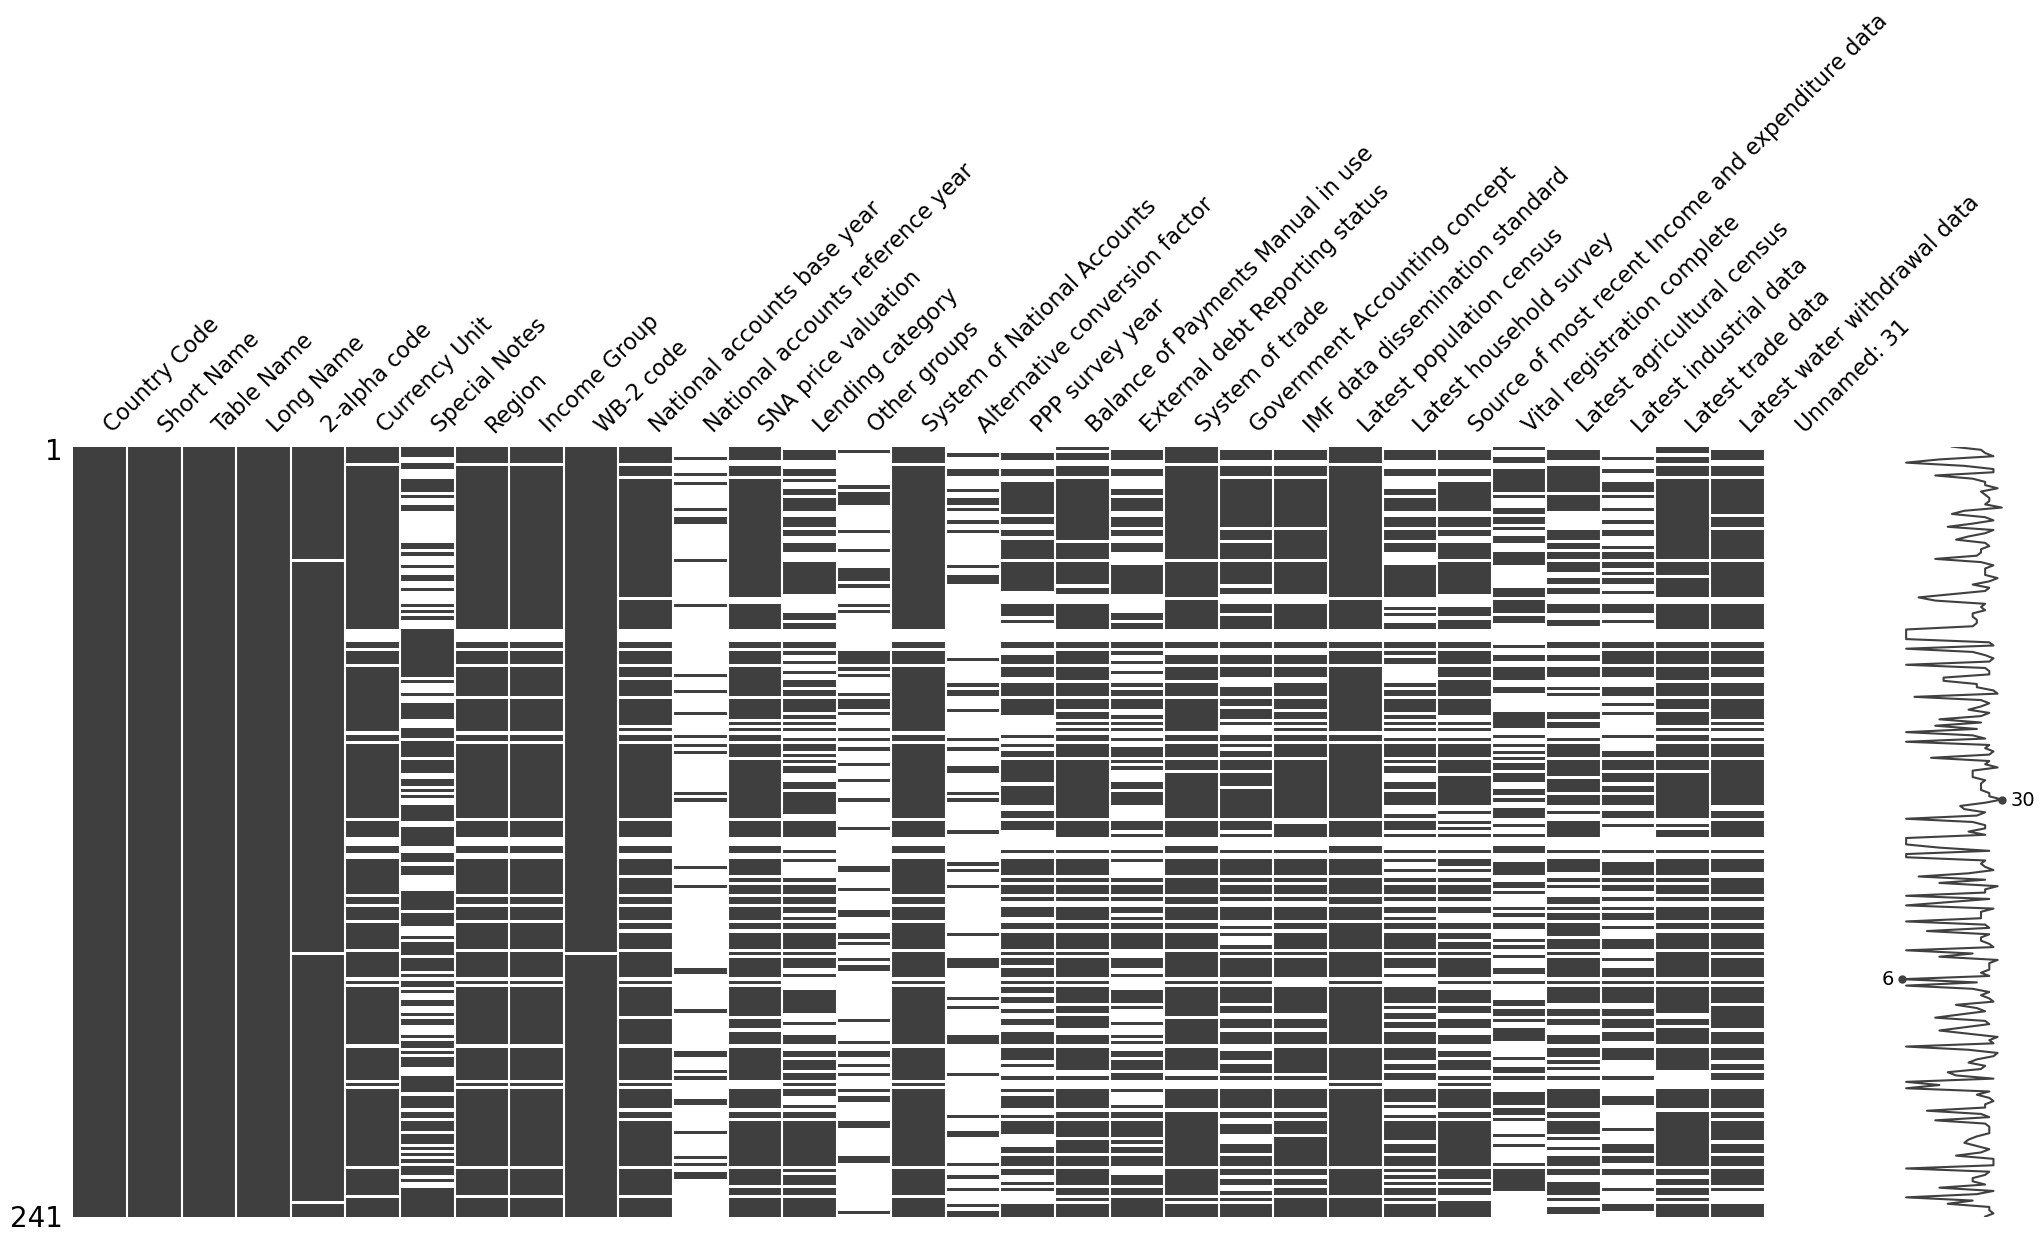

In [10]:
import missingno as msno
%matplotlib inline
msno.matrix(EdStatsCountry)

In [11]:
EdStatsCountry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 32 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Country Code                                       241 non-null    object 
 1   Short Name                                         241 non-null    object 
 2   Table Name                                         241 non-null    object 
 3   Long Name                                          241 non-null    object 
 4   2-alpha code                                       238 non-null    object 
 5   Currency Unit                                      215 non-null    object 
 6   Special Notes                                      145 non-null    object 
 7   Region                                             214 non-null    object 
 8   Income Group                                       214 non-null    object 
 9   WB-2 code 

In [12]:
# Nombre de lignes et de colonnes
EdStatsCountry.shape

(241, 32)

In [13]:
# Taux de valeurs manquantes par colonne
EdStatsCountry.isna().mean()

Country Code                                        0
Short Name                                          0
Table Name                                          0
Long Name                                           0
2-alpha code                                        0
Currency Unit                                       0
Special Notes                                       0
Region                                              0
Income Group                                        0
WB-2 code                                           0
National accounts base year                         0
National accounts reference year                    1
SNA price valuation                                 0
Lending category                                    0
Other groups                                        1
System of National Accounts                         0
Alternative conversion factor                       1
PPP survey year                                     0
Balance of Payments Manual i

In [14]:
# Doublons du code pays
EdStatsCountry.duplicated('Country Code').sum()

0

In [15]:
# Doublons de pays
EdStatsCountry.duplicated('Short Name').sum()

0

In [16]:
EdStatsCountry['Country Code'].unique()

array(['ABW', 'AFG', 'AGO', 'ALB', 'AND', 'ARB', 'ARE', 'ARG', 'ARM',
       'ASM', 'ATG', 'AUS', 'AUT', 'AZE', 'BDI', 'BEL', 'BEN', 'BFA',
       'BGD', 'BGR', 'BHR', 'BHS', 'BIH', 'BLR', 'BLZ', 'BMU', 'BOL',
       'BRA', 'BRB', 'BRN', 'BTN', 'BWA', 'CAF', 'CAN', 'CHE', 'CHI',
       'CHL', 'CHN', 'CIV', 'CMR', 'COD', 'COG', 'COL', 'COM', 'CPV',
       'CRI', 'CUB', 'CUW', 'CYM', 'CYP', 'CZE', 'DEU', 'DJI', 'DMA',
       'DNK', 'DOM', 'DZA', 'EAP', 'EAS', 'ECA', 'ECS', 'ECU', 'EGY',
       'EMU', 'ERI', 'ESP', 'EST', 'ETH', 'EUU', 'FIN', 'FJI', 'FRA',
       'FRO', 'FSM', 'GAB', 'GBR', 'GEO', 'GHA', 'GIB', 'GIN', 'GMB',
       'GNB', 'GNQ', 'GRC', 'GRD', 'GRL', 'GTM', 'GUM', 'GUY', 'HIC',
       'HKG', 'HND', 'HPC', 'HRV', 'HTI', 'HUN', 'IDN', 'IMN', 'IND',
       'IRL', 'IRN', 'IRQ', 'ISL', 'ISR', 'ITA', 'JAM', 'JOR', 'JPN',
       'KAZ', 'KEN', 'KGZ', 'KHM', 'KIR', 'KNA', 'KOR', 'KWT', 'LAC',
       'LAO', 'LBN', 'LBR', 'LBY', 'LCA', 'LCN', 'LDC', 'LIC', 'LIE',
       'LKA', 'LMC',

In [17]:
EdStatsCountry['Short Name'].unique()

array(['Aruba', 'Afghanistan', 'Angola', 'Albania', 'Andorra',
       'Arab World', 'United Arab Emirates', 'Argentina', 'Armenia',
       'American Samoa', 'Antigua and Barbuda', 'Australia', 'Austria',
       'Azerbaijan', 'Burundi', 'Belgium', 'Benin', 'Burkina Faso',
       'Bangladesh', 'Bulgaria', 'Bahrain', 'The Bahamas',
       'Bosnia and Herzegovina', 'Belarus', 'Belize', 'Bermuda',
       'Bolivia', 'Brazil', 'Barbados', 'Brunei', 'Bhutan', 'Botswana',
       'Central African Republic', 'Canada', 'Switzerland',
       'Channel Islands', 'Chile', 'China', "Côte d'Ivoire", 'Cameroon',
       'Dem. Rep. Congo', 'Congo', 'Colombia', 'Comoros', 'Cabo Verde',
       'Costa Rica', 'Cuba', 'Curaçao', 'Cayman Islands', 'Cyprus',
       'Czech Republic', 'Germany', 'Djibouti', 'Dominica', 'Denmark',
       'Dominican Republic', 'Algeria',
       'East Asia & Pacific (developing only)',
       'East Asia & Pacific (all income levels)',
       'Europe & Central Asia (developing only)',


In [18]:
EdStatsCountry['Region'].unique()

array(['Latin America & Caribbean', 'South Asia', 'Sub-Saharan Africa',
       'Europe & Central Asia', nan, 'Middle East & North Africa',
       'East Asia & Pacific', 'North America'], dtype=object)

In [19]:
EdStatsCountry['Income Group'].unique()

array(['High income: nonOECD', 'Low income', 'Upper middle income', nan,
       'Lower middle income', 'High income: OECD'], dtype=object)

In [20]:
EdStatsCountry['Currency Unit'].unique()

array(['Aruban florin', 'Afghan afghani', 'Angolan kwanza',
       'Albanian lek', 'Euro', nan, 'U.A.E. dirham', 'Argentine peso',
       'Armenian dram', 'U.S. dollar', 'East Caribbean dollar',
       'Australian dollar', 'New Azeri manat', 'Burundi franc',
       'CFA franc', 'Bangladeshi taka', 'Bulgarian lev', 'Bahraini dinar',
       'Bahamian dollar', 'Bosnia and Herzegovina convertible mark',
       'Belarusian rubel', 'Belize dollar', 'Bermuda dollar',
       'Bolivian Boliviano', 'Brazilian real', 'Barbados dollar',
       'Brunei dollar', 'Bhutanese ngultrum', 'Botswana pula',
       'Canadian dollar', 'Swiss franc', 'Pound sterling', 'Chilean peso',
       'Chinese yuan', 'Congolese franc', 'Colombian peso',
       'Comorian franc', 'Cabo Verde escudo', 'Costa Rican colon',
       'Cuban peso', 'Netherlands Antilles guilder',
       'Cayman Islands dollar', 'Czech koruna', 'Djibouti franc',
       'Danish krone', 'Dominican peso', 'Algerian dinar',
       'Egyptian pound', '

In [21]:
# Changement des colonnes "années" en int
colonnes_a_convertir = ['Latest industrial data','Latest trade data'] 
EdStatsCountry[colonnes_a_convertir]  = EdStatsCountry[colonnes_a_convertir].astype('Int64')

In [22]:
EdStatsCountry.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,2010,NaN,NaN,Yes,NaN,<NA>,2012,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,<NA>,2012,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,<NA>,<NA>,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010,2012,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,<NA>,2006,NaN,NaN


Il n'y a pas de lignes en doublon dans ce dataframe.

### Analyse du 1er fichier


Table de référence pour décrire chaque pays : 

Géographie : 
- Country Code : code pays à 3 lettres
- Short Name : nom usuel court du pays
- Table Name : nom utilisé dans les tableaux
- Long Name : nom complet du pays
- 2-alpha code : code pays à 2 lettres (norme ISO)
- WB-2 code : autre code pays à 2 caractères

Organisation et classification :
- Region : grande region géographique du pays (ex : Europe & Central Asia)
- Income Group : niveau de revenu du pays
- Lending category : catégorie d'emprunt
- Other groups : appartenance à d'autres regroupements de pays (ex : pays pauvres très endettés)

Economie et monnaie :
- Currency Unit : monnaie nationale utilisée (ex : Euro)
- National accounts base year : l'année de base utilisée pour calculer les comptes nationaux (PIB).
- National accounts reference year : l'année de référence
- SNA price valuation : méthode d'évaluation des prix (prix de base ou prix d'acquisition)
- System of National Accounts : norme comptable nationale utilisée
- Alternative conversion factor : facteur de conversion monétaire alternatif si nécessaire.
- PPP survey year : l'année de l'enquête sur la Parité de Pouvoir d'Achat (PPP)

Indicateurs statistiques et méthodologiques :
- Special Notes : notes explicatives ou des avertissements sur les particularités des données du pays.
- Balance of Payments Manual in use : norme internationale utilisée pour calculer la balance des paiements du pays.
- External debt Reporting statuss : statut de déclaration de la dette extérieure du pays auprès de la banque mondiale.
- System of trade: méthode d'enregistrement ds statistiques du commerce internationale.
- Government Accounting concept : méthode comptable utilisée pour les finances publiques.
- IMF data dissemination standard : niveau de transparence et de diffusion des données statistiques adopté auprès du FMI.
- Latest population census : année du dernier recensement de la population.
- Latest household survey : année de la dernière enquête menée auprès des ménages.
- Source of most recent Income and expenditure data : origine ou type d'enquête utilisé pour mesurer les revenus et dépenses des habitants.
- Vital registration complete : indique si le système d'enregistrement des faits civils (naissances, décès) est complet et fiable.
- Latest agricultural census: dernier recensement agricole.
- Latest industrial data : dernière publication de données sur l'industrie.
- Latest trade data : dernières stats commerciales.
- Latest water withdrawal data  : année de la dernère évaluation des prélèvements d'eau dans le pays.


In [26]:
# Suppression des colonnes vides ou contenants peu de ligne
EdStatsCountry = EdStatsCountry.drop(['National accounts reference year', 'Alternative conversion factor', 'Unnamed: 31'], axis=1)
EdStatsCountry.shape

(241, 29)

### 2ème fichier 

In [28]:
EdStatsCountrySeries.head()

,CountryCode,SeriesCode,DESCRIPTION,Unnamed: 3
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population...,NaN
1,ABW,SP.POP.GROW,Data sources: United Nations World Population ...,NaN
2,AFG,SP.POP.GROW,Data sources: United Nations World Population ...,NaN
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.,NaN
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population...,NaN


In [29]:
EdStatsCountrySeries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 613 entries, 0 to 612
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CountryCode  613 non-null    object 
 1   SeriesCode   613 non-null    object 
 2   DESCRIPTION  613 non-null    object 
 3   Unnamed: 3   0 non-null      float64
dtypes: float64(1), object(3)
memory usage: 19.3+ KB


In [30]:
# Nombre de lignes et de colonnes
EdStatsCountrySeries.shape

(613, 4)

In [31]:
# Taux de valeurs manquantes par colonne
EdStatsCountrySeries.isna().mean()

CountryCode   0
SeriesCode    0
DESCRIPTION   0
Unnamed: 3    1
dtype: float64

In [32]:
EdStatsCountrySeries['SeriesCode'].unique()

array(['SP.POP.TOTL', 'SP.POP.GROW', 'NY.GDP.PCAP.PP.CD',
       'NY.GDP.MKTP.PP.KD', 'NY.GNP.MKTP.PP.CD', 'NY.GDP.MKTP.PP.CD',
       'NY.GDP.PCAP.PP.KD', 'NY.GNP.PCAP.PP.CD', 'SP.POP.1564.TO.ZS',
       'SP.POP.TOTL.MA.ZS', 'SP.POP.TOTL.FE.ZS', 'SP.POP.0014.TO.ZS',
       'NY.GNP.PCAP.CD', 'NY.GDP.PCAP.CD', 'NY.GDP.PCAP.KD',
       'SP.POP.1564.MA.IN', 'SP.POP.0014.TO', 'SP.POP.1564.TO',
       'SP.POP.1564.FE.IN', 'SP.POP.0014.MA.IN', 'SP.POP.0014.FE.IN'],
      dtype=object)

In [33]:
EdStatsCountrySeries['SeriesCode'].nunique()

21

Il n'y a que pour 21 indicateurs que nous avons des infos dans ce dataframe.

### Analyse du 2ème fichier

Précisions sur l'origine ou la fiabilité d'un chiffre d'un pays donné.

In [37]:
# Suppression des colonnes vides ou contenants peu de ligne
EdStatsCountrySeries = EdStatsCountrySeries.drop(['Unnamed: 3'], axis=1)
EdStatsCountrySeries.shape

(613, 3)

### 3ème fichier

In [39]:
EdStatsData.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,55,55,56,57,58,59,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
EdStatsData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 886930 entries, 0 to 886929
Data columns (total 70 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    886930 non-null  object 
 1   Country Code    886930 non-null  object 
 2   Indicator Name  886930 non-null  object 
 3   Indicator Code  886930 non-null  object 
 4   1970            72288 non-null   float64
 5   1971            35537 non-null   float64
 6   1972            35619 non-null   float64
 7   1973            35545 non-null   float64
 8   1974            35730 non-null   float64
 9   1975            87306 non-null   float64
 10  1976            37483 non-null   float64
 11  1977            37574 non-null   float64
 12  1978            37576 non-null   float64
 13  1979            36809 non-null   float64
 14  1980            89122 non-null   float64
 15  1981            38777 non-null   float64
 16  1982            37511 non-null   float64
 17  1983      

In [41]:
# Nombre de lignes et de colonnes
EdStatsData.shape

(886930, 70)

In [42]:
# Taux de valeurs manquantes par colonne
EdStatsData.isna().mean()

Country Name     0 
Country Code     0 
Indicator Name   0 
Indicator Code   0 
1970             1 
                 ..
2085             1 
2090             1 
2095             1 
2100             1 
Unnamed: 69      1 
Length: 70, dtype: float64

### Analyse du 3ème fichier :

Données statistiques mondiales sur l'éducation.
Beaucoup de colonnes "année" sont vides. 

In [45]:
# Suppression de la colonne vide
EdStatsData = EdStatsData.drop(columns=['Unnamed: 69'])

In [46]:
# Colonnes d'identifiants
id_vars = ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code']

In [47]:
# Colonnes année
year_vars = [col for col in EdStatsData.columns if col not in id_vars]
year_vars

['1970',
 '1971',
 '1972',
 '1973',
 '1974',
 '1975',
 '1976',
 '1977',
 '1978',
 '1979',
 '1980',
 '1981',
 '1982',
 '1983',
 '1984',
 '1985',
 '1986',
 '1987',
 '1988',
 '1989',
 '1990',
 '1991',
 '1992',
 '1993',
 '1994',
 '1995',
 '1996',
 '1997',
 '1998',
 '1999',
 '2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013',
 '2014',
 '2015',
 '2016',
 '2017',
 '2020',
 '2025',
 '2030',
 '2035',
 '2040',
 '2045',
 '2050',
 '2055',
 '2060',
 '2065',
 '2070',
 '2075',
 '2080',
 '2085',
 '2090',
 '2095',
 '2100']

In [48]:
# Modification du dataframe pour avoir les années dans les lignes
EdStatsData = pd.melt(EdStatsData, id_vars = id_vars, value_vars=year_vars, var_name='Year', value_name='Value')

In [49]:
EdStatsData.shape

(57650450, 6)

In [50]:
EdStatsData.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,1970,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,1970,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,1970,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,1970,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,1970,55


In [51]:
EdStatsData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57650450 entries, 0 to 57650449
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Country Name    object 
 1   Country Code    object 
 2   Indicator Name  object 
 3   Indicator Code  object 
 4   Year            object 
 5   Value           float64
dtypes: float64(1), object(5)
memory usage: 2.6+ GB


In [52]:
# Convertion de la colonne year en int
EdStatsData['Year'] = pd.to_numeric(EdStatsData['Year'])

In [53]:
# Suppression des lignes sans donnée dans la colonne "Value"
EdStatsData = EdStatsData.dropna(subset=['Value'])

In [54]:
# Vérifications que toutes les lignes sans valeur ont été supprimées
EdStatsData.isna().mean()

Country Name     0
Country Code     0
Indicator Name   0
Indicator Code   0
Year             0
Value            0
dtype: float64

In [55]:
EdStatsData.shape

(5082201, 6)

91,8% des lignes ont été supprimées

### 4ème fichier

In [58]:
EdStatsFootNote.head()

,CountryCode,SeriesCode,Year,DESCRIPTION,Unnamed: 4
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.,NaN
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.,NaN
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.,NaN
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.,NaN
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.,NaN


In [59]:
EdStatsFootNote.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 643638 entries, 0 to 643637
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   CountryCode  643638 non-null  object 
 1   SeriesCode   643638 non-null  object 
 2   Year         643638 non-null  object 
 3   DESCRIPTION  643638 non-null  object 
 4   Unnamed: 4   0 non-null       float64
dtypes: float64(1), object(4)
memory usage: 24.6+ MB


In [60]:
# Nombre de lignes et de colonnes
EdStatsFootNote.shape

(643638, 5)

In [61]:
# Taux de valeurs manquantes par colonne
EdStatsFootNote.isna().mean()

CountryCode   0
SeriesCode    0
Year          0
DESCRIPTION   0
Unnamed: 4    1
dtype: float64

In [62]:
# Suppression de la colonne vide
EdStatsFootNote = EdStatsFootNote.drop(columns=['Unnamed: 4'])

### Analyse du 4ème fichier

Table de métadonnées et de notes de bas de page du 3ème ficher (EdStatsData)
- CountryCode  : code du pays
- SeriesCode : correspond au Indicator Code du fichier principal

### 5ème fichier

In [66]:
EdStatsSeries.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,...,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type,Unnamed: 20
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...,Percentage of population age 15-19 with no edu...,Percentage of population age 15-19 with no edu...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15+ with n...,Percentage of female population age 15+ with n...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ wi...,Percentage of population age 15+ with no educa...,Percentage of population age 15+ with no educa...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 20-24 with...,Percentage of female population age 20-24 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [67]:
EdStatsSeries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3665 entries, 0 to 3664
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          3665 non-null   object 
 1   Topic                                3665 non-null   object 
 2   Indicator Name                       3665 non-null   object 
 3   Short definition                     2156 non-null   object 
 4   Long definition                      3665 non-null   object 
 5   Unit of measure                      0 non-null      float64
 6   Periodicity                          99 non-null     object 
 7   Base Period                          314 non-null    object 
 8   Other notes                          552 non-null    object 
 9   Aggregation method                   47 non-null     object 
 10  Limitations and exceptions           14 non-null     object 
 11  Notes from original source    

In [68]:
# Nombre de lignes et de colonnes
EdStatsSeries.shape

(3665, 21)

In [69]:
# Taux de valeurs manquantes par colonne
EdStatsSeries.isna().mean()

Series Code                           0
Topic                                 0
Indicator Name                        0
Short definition                      0
Long definition                       0
Unit of measure                       1
Periodicity                           1
Base Period                           1
Other notes                           1
Aggregation method                    1
Limitations and exceptions            1
Notes from original source            1
General comments                      1
Source                                0
Statistical concept and methodology   1
Development relevance                 1
Related source links                  1
Other web links                       1
Related indicators                    1
License Type                          1
Unnamed: 20                           1
dtype: float64

In [70]:
# Suppression des colonnes vides
EdStatsSeries = EdStatsSeries.drop(columns=['Unit of measure',
                                            'Notes from original source',
                                            'Other web links',
                                            'Related indicators',
                                            'License Type','Unnamed: 20'])

In [71]:
EdStatsSeries.shape


(3665, 15)

### Analyse du 5ème fichier

C'est le dictionnaire des indicateurs du fichier principal : 3665 lignes qui correspondent au nombre total d'indicateurs uniques de la base. 
- Series Code et Indicator Name : identifiants uniques qui permettent de faire la jointure avec le fichier principal EdStatsData.
- Topic : thématique générale de l'indicateur (ex: Éducation des adultes, Dépenses publiques, Enseignement primaire, etc.).
- Long definition et short definition : définitions détaillées de ce que mesure l'indicateur.
- Source : l'organisme qui a produit la donnée.
  

### Analyse globale :
- EdStatsCountry : caractéristiques des pays.
- EdStatsCountrySeries : sources des indicateurs pour un pays donné.
- EdStatsData : fichier principal avec les données par pays et par année.
- EdStatsFootNote : notes explicatives par pays, indicateur et année.
- EdStatsSeries : dictionnaire des indicateurs.

## Etape 3 : Realisez le 1er nettoyage

In [76]:
# Identification des faux pays dans le fichier EdStatsCountry

faux_pays = [
    'Arab World', 
    'East Asia & Pacific (developing only)',
    'East Asia & Pacific (all income levels)',
    'Europe & Central Asia (developing only)',
    'Europe & Central Asia (all income levels)',
    'Euro area',
    'European Union',
    'High income',
    'Heavily indebted poor countries (HIPC)',
    'Latin America & Caribbean (developing only)',
    'Latin America & Caribbean (all income levels)',
    'Least developed countries: UN classification',
    'Low income',
    'Lower middle income',
    'Low & middle income',
    'Middle East & North Africa (all income levels)',
    'Middle income',
    'Middle East & North Africa (developing only)',
    'North America',
    'OECD members',
    'South Asia',
    'Sub-Saharan Africa (developing only)',
    'Sub-Saharan Africa (all income levels)',
    'Upper middle income',
    'World'
]


In [77]:
# Suppression des lignes correspondantes à ces faux pays

EdStatsCountry_clean = EdStatsCountry[~EdStatsCountry['Short Name'].isin(faux_pays)]
EdStatsCountry_clean['Short Name'].unique()

array(['Aruba', 'Afghanistan', 'Angola', 'Albania', 'Andorra',
       'United Arab Emirates', 'Argentina', 'Armenia', 'American Samoa',
       'Antigua and Barbuda', 'Australia', 'Austria', 'Azerbaijan',
       'Burundi', 'Belgium', 'Benin', 'Burkina Faso', 'Bangladesh',
       'Bulgaria', 'Bahrain', 'The Bahamas', 'Bosnia and Herzegovina',
       'Belarus', 'Belize', 'Bermuda', 'Bolivia', 'Brazil', 'Barbados',
       'Brunei', 'Bhutan', 'Botswana', 'Central African Republic',
       'Canada', 'Switzerland', 'Channel Islands', 'Chile', 'China',
       "Côte d'Ivoire", 'Cameroon', 'Dem. Rep. Congo', 'Congo',
       'Colombia', 'Comoros', 'Cabo Verde', 'Costa Rica', 'Cuba',
       'Curaçao', 'Cayman Islands', 'Cyprus', 'Czech Republic', 'Germany',
       'Djibouti', 'Dominica', 'Denmark', 'Dominican Republic', 'Algeria',
       'Ecuador', 'Egypt', 'Eritrea', 'Spain', 'Estonia', 'Ethiopia',
       'Finland', 'Fiji', 'France', 'Faeroe Islands', 'Micronesia',
       'Gabon', 'United Kingdom

In [78]:
EdStatsCountry_clean['Short Name'].nunique()

216

Suppression de 241 - 216 =  25 "faux" pays

In [80]:
# Suppression de ces faux pays dans les autres dataframes
# Utilisation d'une jointure INNER qui ne garde que les lignes communes aux 2 tables

EdStatsCountrySeries_clean = pd.merge(EdStatsCountrySeries, 
                                      EdStatsCountry_clean[['Country Code']], 
                                      left_on='CountryCode', 
                                      right_on='Country Code',
                                      how='inner')

In [81]:
EdStatsCountrySeries_clean.head()

,CountryCode,SeriesCode,DESCRIPTION,Country Code
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population...,ABW
1,ABW,SP.POP.GROW,Data sources: United Nations World Population ...,ABW
2,AFG,SP.POP.GROW,Data sources: United Nations World Population ...,AFG
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.,AFG
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population...,AFG


In [82]:
EdStatsFootNote_clean = pd.merge(EdStatsFootNote, 
                                      EdStatsCountry_clean[['Country Code']], 
                                      left_on='CountryCode', 
                                      right_on='Country Code',
                                      how='inner')

In [83]:
EdStatsFootNote_clean.head()

,CountryCode,SeriesCode,Year,DESCRIPTION,Country Code
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.,ABW
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.,ABW
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.,ABW
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.,ABW
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.,ABW


In [84]:
EdStatsData_clean = pd.merge(EdStatsData, 
                                      EdStatsCountry_clean[['Country Code']], 
                                      on='Country Code',
                                      how='inner')

In [85]:
EdStatsData_clean.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
0,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP.FE,1970,0
1,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP,1970,0
2,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519.FE,1970,0
3,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519,1970,1
4,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.2024.FE,1970,0


In [86]:
EdStatsData_clean.shape

(4792458, 6)

# Exercice partie 2

## Etape 1 - Reduisez le périmètre en utilisant une approche métier

### Réduction du nombre d'indicateurs

In [90]:
# Liste des catégories métier auxquelles appartient chaque indicateur
EdStatsSeries['Topic'].unique()

array(['Attainment', 'Education Equality',
       'Infrastructure: Communications', 'Learning Outcomes',
       'Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators',
       'Economic Policy & Debt: National accounts: US$ at constant 2010 prices: Aggregate indicators',
       'Economic Policy & Debt: Purchasing power parity',
       'Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita',
       'Teachers', 'Education Management Information Systems (SABER)',
       'Early Child Development (SABER)',
       'Engaging the Private Sector (SABER)',
       'School Health and School Feeding (SABER)',
       'School Autonomy and Accountability (SABER)',
       'School Finance (SABER)', 'Student Assessment (SABER)',
       'Teachers (SABER)', 'Tertiary Education (SABER)',
       'Workforce Development (SABER)', 'Literacy', 'Background',
       'Primary', 'Secondary', 'Tertiary', 'Early Childhood Education',
       'Pre-Primary', 'Expenditures'

In [91]:
#Nombre de catégories métier
EdStatsSeries['Topic'].nunique()

37

In [92]:
# Nombre d'indicateurs différents
EdStatsSeries['Indicator Name'].nunique()

3665

In [93]:
# Reduction du nombre de thèmes : on garde les plus pertinents pour le projet (10)
themes = [
    'Secondary',                        # lycée
    'Tertiary',                         # université
    'Post-Secondary/Non-Tertiary',      # formations post-bac
    'Attainment',                       # niveaux de diplômes de la population
    'Education Equality',               # égalité d'accès
    'Learning Outcomes',                # résultats et compétences
    'Expenditures',                     # budgets consacrés à l'éducation
    'Population',                       # données démographiques
    'Infrastructure: Communications',   # infrastructures de communication
    'Tertiary Education (SABER)',       # politiques publiques pour l'enseignement supérieur
    'Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators'

]

In [94]:
# On filtre EdStatsSeries pour ne garder que ces thèmes
EdStatsSeries_filtre = EdStatsSeries[EdStatsSeries['Topic'].isin(themes)]
EdStatsSeries_filtre['Topic'].unique()

array(['Attainment', 'Education Equality',
       'Infrastructure: Communications', 'Learning Outcomes',
       'Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators',
       'Tertiary Education (SABER)', 'Secondary', 'Tertiary',
       'Expenditures', 'Population', 'Post-Secondary/Non-Tertiary'],
      dtype=object)

In [95]:
EdStatsSeries_filtre['Series Code'].nunique()

2966

Il reste 2966 indicateurs différents après le filtre sur les catégories métiers en lien avec les systèmes éducatifs.

In [97]:
# On récupère les indicateurs correspondants
indicateurs = EdStatsSeries_filtre['Series Code'].tolist()


In [98]:
indicateurs

['BAR.NOED.1519.FE.ZS',
 'BAR.NOED.1519.ZS',
 'BAR.NOED.15UP.FE.ZS',
 'BAR.NOED.15UP.ZS',
 'BAR.NOED.2024.FE.ZS',
 'BAR.NOED.2024.ZS',
 'BAR.NOED.2529.FE.ZS',
 'BAR.NOED.2529.ZS',
 'BAR.NOED.25UP.FE.ZS',
 'BAR.NOED.25UP.ZS',
 'BAR.NOED.3034.FE.ZS',
 'BAR.NOED.3034.ZS',
 'BAR.NOED.3539.FE.ZS',
 'BAR.NOED.3539.ZS',
 'BAR.NOED.4044.FE.ZS',
 'BAR.NOED.4044.ZS',
 'BAR.NOED.4549.FE.ZS',
 'BAR.NOED.4549.ZS',
 'BAR.NOED.5054.FE.ZS',
 'BAR.NOED.5054.ZS',
 'BAR.NOED.5559.FE.ZS',
 'BAR.NOED.5559.ZS',
 'BAR.NOED.6064.FE.ZS',
 'BAR.NOED.6064.ZS',
 'BAR.NOED.6569.FE.ZS',
 'BAR.NOED.6569.ZS',
 'BAR.NOED.7074.FE.ZS',
 'BAR.NOED.7074.ZS',
 'BAR.NOED.75UP.FE.ZS',
 'BAR.NOED.75UP.ZS',
 'BAR.POP.1519',
 'BAR.POP.1519.FE',
 'BAR.POP.15UP',
 'BAR.POP.15UP.FE',
 'BAR.POP.2024',
 'BAR.POP.2024.FE',
 'BAR.POP.2529',
 'BAR.POP.2529.FE',
 'BAR.POP.25UP',
 'BAR.POP.25UP.FE',
 'BAR.POP.3034',
 'BAR.POP.3034.FE',
 'BAR.POP.3539',
 'BAR.POP.3539.FE',
 'BAR.POP.4044',
 'BAR.POP.4044.FE',
 'BAR.POP.4549',
 'BAR.POP.45

In [99]:
# Suppression des lignes inutiles dans les différents jeux de données
EdStatsCountrySeries_filtre = EdStatsCountrySeries_clean[EdStatsCountrySeries_clean['SeriesCode'].isin(indicateurs)]
EdStatsData_filtre = EdStatsData_clean[EdStatsData_clean['Indicator Code'].isin(indicateurs)]
EdStatsFootNote_filtre = EdStatsFootNote_clean[EdStatsFootNote_clean['SeriesCode'].isin(indicateurs)]

In [100]:
EdStatsCountrySeries_filtre.head()

,CountryCode,SeriesCode,DESCRIPTION,Country Code
128,CYP,NY.GDP.PCAP.CD,Data are for areas under the effective control...,CYP
189,GEO,NY.GDP.PCAP.CD,Excludes Abkhazia and South Ossetia.,GEO
317,MAR,NY.GDP.PCAP.CD,Includes Former Spanish Sahara.,MAR
329,MDA,NY.GDP.PCAP.CD,Excludes Transnistria.,MDA
557,TZA,NY.GDP.PCAP.CD,Covers mainland Tanzania only.,TZA


In [101]:
EdStatsCountrySeries_filtre.shape

(5, 4)

In [102]:
EdStatsData_filtre.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
0,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP.FE,1970,0
1,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP,1970,0
2,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519.FE,1970,0
3,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519,1970,1
4,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.2024.FE,1970,0


In [103]:
EdStatsData_filtre.shape


(3643235, 6)

In [104]:
EdStatsFootNote_filtre.head()

,CountryCode,SeriesCode,Year,DESCRIPTION,Country Code
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.,ABW
6,ABW,SE.SEC.ENRL.VO.FE,YR2005,Country estimation.,ABW
7,ABW,SE.SEC.ENRL.GC,YR2003,Country estimation.,ABW
12,ABW,SE.SEC.ENRL.VO.FE.ZS,YR2002,Country estimation.,ABW
14,ABW,SE.SEC.ENRL.VO.FE.ZS,YR2007,Country estimation.,ABW


In [105]:
EdStatsFootNote_filtre.shape

(236935, 5)

### Interprétation des colonnes du fichier data

Le fait d'avoir des valeurs dans les années futures correspondent à des projections et non à de vrais chiffres, nous pouvons donc les supprimer.
De plus, la startup EdTech propose des outils numériques, il n'est donc pas judicieux de garder les années trop anciennes, nous pouvons donc garder uniquement les 10 dernières années recensées pour connaître les dernières tendances de chaque pays .

In [108]:
print(EdStatsData_filtre['Year'].min())
print(EdStatsData_filtre['Year'].max())

1970
2100


In [109]:
# On crée les listes des années à supprimer
annees_passees_a_supprimer = np.arange(1970, 2005)
annees_futures_a_supprimer = np.arange(2018, 2101)

In [110]:
# On filtre le dataframe
EdStatsData_filtre = EdStatsData_filtre[~EdStatsData_filtre['Year'].isin(annees_passees_a_supprimer)]
EdStatsData_final = EdStatsData_filtre[~EdStatsData_filtre['Year'].isin(annees_futures_a_supprimer)]


In [111]:
# On vérifie la dernière année renseignée pour chaque pays
derniere_annee = EdStatsData_final.groupby('Country Name')['Year'].max()
derniere_annee_df = derniere_annee.reset_index()
derniere_annee_df

,Country Name,Year
0,Afghanistan,2016
1,Albania,2016
2,Algeria,2016
3,American Samoa,2016
4,Andorra,2016
...,...,...
210,Virgin Islands (U.S.),2016
211,West Bank and Gaza,2016
212,"Yemen, Rep.",2016
213,Zambia,2016


In [112]:
derniere_annee_df['Year'].unique()

array([2016, 2017, 2007, 2015], dtype=int64)

In [113]:
# On vérifie quel(s) pays n'a rien renseigné depuis 2007 et on supprime ce(s) pays 
pays_2007 = derniere_annee_df[derniere_annee_df['Year'] == 2007]
pays_2007

,Country Name,Year
38,Channel Islands,2007


In [114]:
# On supprime ce pays qui n'a pas de données assez récentes
EdStatsData_final = EdStatsData_final[~EdStatsData_final['Country Name'].isin(pays_2007)]


In [115]:
EdStatsData_final.shape

(1158220, 6)

In [116]:
EdStatsData_final.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
2339303,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP.FE,2005,1
2339304,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP,2005,2
2339305,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519.FE,2005,1
2339306,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519,2005,2
2339307,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.2024.FE,2005,2


Suppression de 2 468 195 lignes dans le dataframe EdStatsData_final et réduction des années à la période 2005-2017 pour avoir au moins 10 ans de données pour chaque pays.

In [118]:
EdStatsData_final['Indicator Name'].value_counts()

Indicator Name
Theoretical duration of upper secondary education (years)                                                 2416
Internet users (per 100 people)                                                                           2416
Official entrance age to lower secondary education (years)                                                2416
Theoretical duration of secondary education (years)                                                       2416
GDP at market prices (current US$)                                                                        2405
                                                                                                          ... 
EGRA: Reading Comprehension - Share of students scoring at least 80 percent (%). Hararigna. 2nd Grade        1
EGRA: Reading Comprehension - Share of students scoring at least 80 percent (%). Amharic. 3rd Grade          1
EGRA: Oral Reading Fluency - Correct Words Read Per Minute (Mean). Spanish. 3rd Grade            

In [119]:
EdStatsData_final['Indicator Name'].nunique()

2929

In [120]:
EdStatsData_final['Country Name'].nunique()

215

## Etape 2 - Réduisez le périmètre en utilisant une approche data

In [122]:
# Vérification des valeurs nulles dans le dataframe principal
EdStatsData_final.isnull().sum()

Country Name      0
Country Code      0
Indicator Name    0
Indicator Code    0
Year              0
Value             0
dtype: int64

In [123]:
# Nombre d'indicateurs différents
nb_total_indicateurs = EdStatsData_final['Indicator Code'].nunique()
nb_total_indicateurs

2929

In [124]:
# Nombre d'années
nb_total_annees = EdStatsData_final['Year'].nunique()
nb_total_annees

13

In [125]:
# Nombre d'indicateurs différents par année
nb_indicateurs_par_an = EdStatsData_final.groupby('Year')['Indicator Code'].nunique()
nb_indicateurs_par_an

Year
2005    1550
2006    1444
2007    1358
2008    1134
2009    1251
2010    2022
2011    1381
2012    1413
2013    1226
2014    1351
2015    1485
2016     157
2017      17
Name: Indicator Code, dtype: int64

In [126]:
# Proportion d'indicateurs par année 
proportion_indicateurs_par_an = (nb_indicateurs_par_an/nb_total_indicateurs).sort_values(ascending=False)
proportion_indicateurs_par_an

Year
2010   1
2005   1
2015   1
2006   0
2012   0
2011   0
2007   0
2014   0
2009   0
2013   0
2008   0
2016   0
2017   0
Name: Indicator Code, dtype: float64

In [127]:
nb_annee_par_indicateur = EdStatsData_final.groupby('Indicator Code')['Year'].nunique()
nb_annee_par_indicateur

Indicator Code
BAR.NOED.1519.FE.ZS             2
BAR.NOED.1519.ZS                2
BAR.NOED.15UP.FE.ZS             2
BAR.NOED.15UP.ZS                2
BAR.NOED.2024.FE.ZS             2
                               ..
UIS.XUNIT.USCONST.3.FSGOV      10
UIS.XUNIT.USCONST.4.FSGOV      10
UIS.XUNIT.USCONST.56.FSGOV     10
XGDP.23.FSGOV.FDINSTADM.FFD    11
XGDP.56.FSGOV.FDINSTADM.FFD    11
Name: Year, Length: 2929, dtype: int64

In [128]:
proportion_annees_par_indicateur = (nb_annee_par_indicateur/nb_total_annees).sort_values(ascending=False)
proportion_annees_par_indicateur

Indicator Code
SP.PRM.GRAD.MA           1 
SE.TER.GRAD.SV.ZS        1 
UIS.EA.5T8.AG25T99.F     1 
UIS.EA.5T8.AG25T99       1 
UIS.EA.3T6.AG25T99.M     1 
                         ..
LO.EGRA.NCWPM.SPN.2GRD   0 
LO.EGRA.NCWPM.SOM.3GRD   0 
LO.EGRA.NCWPM.SOM.2GRD   0 
LO.EGRA.NCWPM.SNG.2GRD   0 
LO.LLECE.MAT6.P10        0 
Name: Year, Length: 2929, dtype: float64

In [129]:
# Calcul pour chaque année la proportion d'indicateurs, pour chaque indicateur la proportion d'années renseignées
def calcul_proportions(df):
    """
    Calcule pour chaque année la proportion d'indicateurs, pour chaque indicateur la proportion d'années renseignées.
    """
    nb_total_indicateurs = df['Indicator Code'].nunique()
    nb_total_annees = df['Year'].nunique()

    # Pour chaque année, calcul de la proportion d'indicateurs
    nb_indicateurs_par_an = df.groupby('Year')['Indicator Code'].nunique()
    proportion_indicateurs_par_an = (nb_indicateurs_par_an/nb_total_indicateurs).sort_values(ascending=False)

    # Pour chaque indicateurs, proportion d'années renseignées
    nb_annee_par_indicateur = df.groupby('Indicator Code')['Year'].nunique()
    proportion_annees_par_indicateur = (nb_annee_par_indicateur/nb_total_annees).sort_values(ascending=False)

    return df, proportion_indicateurs_par_an, proportion_annees_par_indicateur

In [130]:
df, proportion_annee, proportion_indicateur = calcul_proportions(EdStatsData_final)


In [131]:
df

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
2339303,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP.FE,2005,1
2339304,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.15UP,2005,2
2339305,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519.FE,2005,1
2339306,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.1519,2005,2
2339307,Afghanistan,AFG,"Barro-Lee: Average years of primary schooling,...",BAR.PRM.SCHL.2024.FE,2005,2
...,...,...,...,...,...,...
3923231,Sierra Leone,SLE,SABER: (Tertiary Education) Policy Goal 5: Qua...,SABER.TER.GOAL5,2017,1
3923232,Sierra Leone,SLE,SABER: (Tertiary Education) Policy Goal 6 Leve...,SABER.TER.GOAL6.LVL1,2017,2
3923233,Sierra Leone,SLE,SABER: (Tertiary Education) Policy Goal 6 Leve...,SABER.TER.GOAL6.LVL2,2017,1
3923234,Sierra Leone,SLE,SABER: (Tertiary Education) Policy Goal 6 Leve...,SABER.TER.GOAL6.LVL3,2017,2


In [132]:
proportion_annee

Year
2010   1
2005   1
2015   1
2006   0
2012   0
2011   0
2007   0
2014   0
2009   0
2013   0
2008   0
2016   0
2017   0
Name: Indicator Code, dtype: float64

In [133]:
proportion_indicateur

Indicator Code
SP.PRM.GRAD.MA           1 
SE.TER.GRAD.SV.ZS        1 
UIS.EA.5T8.AG25T99.F     1 
UIS.EA.5T8.AG25T99       1 
UIS.EA.3T6.AG25T99.M     1 
                         ..
LO.EGRA.NCWPM.SPN.2GRD   0 
LO.EGRA.NCWPM.SOM.3GRD   0 
LO.EGRA.NCWPM.SOM.2GRD   0 
LO.EGRA.NCWPM.SNG.2GRD   0 
LO.LLECE.MAT6.P10        0 
Name: Year, Length: 2929, dtype: float64

In [134]:
seuil_annee=0.30
seuil_indicateur=0.30

In [135]:
annees_a_garder = proportion_indicateurs_par_an[proportion_indicateurs_par_an >= seuil_annee].index
annees_a_garder.sort_values()

Index([2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015], dtype='int64', name='Year')

In [136]:
indicateurs_a_garder = proportion_annees_par_indicateur[proportion_annees_par_indicateur >= seuil_indicateur].index
indicateurs_a_garder

Index(['SP.PRM.GRAD.MA', 'SE.TER.GRAD.SV.ZS', 'UIS.EA.5T8.AG25T99.F',
       'UIS.EA.5T8.AG25T99', 'UIS.EA.3T6.AG25T99.M', 'UIS.EA.3T6.AG25T99.F',
       'UIS.EA.3T6.AG25T99', 'SE.XPD.TERT.ZS', 'SE.XPD.TERT.PC.ZS',
       'SE.XPD.SECO.ZS',
       ...
       'LO.PASEC.MAT.P10', 'LO.PASEC.MAT.P05', 'LO.PASEC.FRE.P95',
       'LO.PASEC.FRE.P90', 'LO.PASEC.FRE.P75', 'LO.PASEC.FRE.P50',
       'LO.PASEC.FRE.P25', 'LO.PASEC.FRE.P10', 'LO.PASEC.FRE.P05',
       'LO.PASEC.MAT.P25'],
      dtype='object', name='Indicator Code', length=1335)

In [137]:
indicateurs_a_garder.nunique()

1335

In [138]:
# On complète la fonction avec les notions de seuils
def calcul_proportions(df, seuil_annee, seuil_indicateur):
    """
    Calcule pour chaque année la proportion d'indicateurs, pour chaque indicateur la proportion d'années renseignées.
    """
    nb_total_indicateurs = df['Indicator Code'].nunique()
    nb_total_annees = df['Year'].nunique()

    # Pour chaque année, calcul de la proportion d'indicateurs
    nb_indicateurs_par_an = df.groupby('Year')['Indicator Code'].nunique()
    proportion_indicateurs_par_an = (nb_indicateurs_par_an/nb_total_indicateurs).sort_values(ascending=False)

    # Pour chaque indicateurs, proportion d'années renseignées
    nb_annee_par_indicateur = df.groupby('Indicator Code')['Year'].nunique()
    proportion_annees_par_indicateur = (nb_annee_par_indicateur/nb_total_annees).sort_values(ascending=False)

    # Réduire les données en fonction des seuils
    annees_a_garder = proportion_indicateurs_par_an[proportion_indicateurs_par_an > seuil_annee].index
    indicateurs_a_garder = proportion_annees_par_indicateur[proportion_annees_par_indicateur > seuil_indicateur].index
    df_reduit = df[df['Year'].isin(annees_a_garder) & df['Indicator Code'].isin(indicateurs_a_garder)]

    # Bilan
    print(f"Lignes avant calcul : {df.shape[0]}")
    print(f"Lignes après calcul : {df_reduit.shape[0]}")
    print(f"Lignes supprimés  : {df.shape[0] - df_reduit.shape[0]} soit {round((df_reduit.shape[0] / df.shape[0])*100 - 100, 2)}% ")

    print(f"Années conservées : {annees_a_garder.nunique()} sur {nb_total_annees}")
    print(f"Indicateurs conservés : {indicateurs_a_garder.nunique()} sur {nb_total_indicateurs} soit {round((indicateurs_a_garder.nunique() / nb_total_indicateurs)*100, 2)}% ")

    return df_reduit, proportion_indicateurs_par_an, proportion_annees_par_indicateur

In [139]:
df, proportion_annee, proportion_indicateur = calcul_proportions(EdStatsData_final, 0.30, 0.30)

Lignes avant calcul : 1158220
Lignes après calcul : 924110
Lignes supprimés  : 234110 soit -20.21% 
Années conservées : 11 sur 13
Indicateurs conservés : 1335 sur 2929 soit 45.58% 


In [140]:
# On calcule le nombre de pays avec une valeur renseignée par indicateur et par année 
nb_pays_par_an_et_par_indic = df.groupby(['Indicator Code', 'Indicator Name', 'Year'])['Country Code'].nunique().reset_index()
nb_pays_par_an_et_par_indic

,Indicator Code,Indicator Name,Year,Country Code
0,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2005,16
1,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2006,9
2,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2007,9
3,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2008,9
4,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2009,5
...,...,...,...,...
12938,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2011,99
12939,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2012,83
12940,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2013,73
12941,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2014,35


In [141]:
# On renomme la colonne 
nb_pays_par_an_et_par_indic.rename(columns={'Country Code': 'Nb_pays_renseignes'}, inplace=True)
nb_pays_par_an_et_par_indic

,Indicator Code,Indicator Name,Year,Nb_pays_renseignes
0,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2005,16
1,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2006,9
2,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2007,9
3,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2008,9
4,HH.DHS.GAR.456,DHS: Gross attendance rate. Post Secondary,2009,5
...,...,...,...,...
12938,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2011,99
12939,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2012,83
12940,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2013,73
12941,XGDP.56.FSGOV.FDINSTADM.FFD,Government expenditure in tertiary institution...,2014,35


In [142]:
nb_pays_par_an_et_par_indic = nb_pays_par_an_et_par_indic.sort_values(by='Nb_pays_renseignes', ascending=False)
nb_pays_par_an_et_par_indic.head(50)

,Indicator Code,Indicator Name,Year,Nb_pays_renseignes
2720,NY.GDP.MKTP.CD,GDP at market prices (current US$),2006,205
2731,NY.GDP.PCAP.CD,GDP per capita (current US$),2006,205
2871,SE.SEC.DURS,Theoretical duration of secondary education (y...,2014,204
2820,SE.SEC.AGES,Official entrance age to lower secondary educa...,2007,204
2821,SE.SEC.AGES,Official entrance age to lower secondary educa...,2008,204
2822,SE.SEC.AGES,Official entrance age to lower secondary educa...,2009,204
2823,SE.SEC.AGES,Official entrance age to lower secondary educa...,2010,204
2826,SE.SEC.AGES,Official entrance age to lower secondary educa...,2013,204
2827,SE.SEC.AGES,Official entrance age to lower secondary educa...,2014,204
2828,SE.SEC.AGES,Official entrance age to lower secondary educa...,2015,204


In [143]:
nb_pays_par_an_et_par_indic.shape

(12943, 4)

In [144]:
nb_pays_par_an_et_par_indic['Nb_pays_renseignes'].unique()

array([205, 204, 203, 202, 201, 200, 199, 198, 197, 196, 195, 194, 193,
       192, 191, 190, 189, 188, 187, 186, 185, 184, 183, 181, 174, 173,
       171, 170, 169, 168, 167, 166, 165, 164, 163, 162, 161, 160, 159,
       158, 157, 156, 155, 154, 153, 152, 151, 150, 149, 148, 147, 146,
       145, 144, 143, 142, 141, 140, 139, 138, 137, 136, 135, 134, 133,
       132, 131, 130, 129, 128, 127, 126, 125, 124, 123, 122, 121, 120,
       119, 118, 117, 116, 115, 114, 113, 112, 111, 110, 109, 108, 107,
       106, 105, 104, 103, 102, 101, 100,  99,  98,  97,  96,  95,  94,
        93,  92,  91,  90,  89,  88,  87,  86,  85,  84,  83,  82,  81,
        80,  79,  78,  77,  76,  75,  74,  73,  72,  71,  70,  69,  68,
        67,  66,  65,  64,  63,  62,  61,  60,  59,  58,  57,  56,  55,
        54,  53,  52,  51,  50,  49,  48,  47,  46,  45,  44,  43,  42,
        41,  40,  39,  38,  37,  36,  35,  34,  33,  32,  31,  30,  29,
        28,  27,  26,  25,  24,  23,  22,  21,  20,  19,  18,  1

Comme on a 216 pays, on décide de garder uniquement les indicateurs qui sont renseignées pour au moins 125 pays 

In [146]:
# Suppression des lignes avec moins de 125 pays renseignés par indicateur et par année
nb_pays_par_an_et_par_indic_filtre = nb_pays_par_an_et_par_indic[nb_pays_par_an_et_par_indic['Nb_pays_renseignes'] >= 125]
nb_pays_par_an_et_par_indic_filtre['Nb_pays_renseignes'].unique()

array([205, 204, 203, 202, 201, 200, 199, 198, 197, 196, 195, 194, 193,
       192, 191, 190, 189, 188, 187, 186, 185, 184, 183, 181, 174, 173,
       171, 170, 169, 168, 167, 166, 165, 164, 163, 162, 161, 160, 159,
       158, 157, 156, 155, 154, 153, 152, 151, 150, 149, 148, 147, 146,
       145, 144, 143, 142, 141, 140, 139, 138, 137, 136, 135, 134, 133,
       132, 131, 130, 129, 128, 127, 126, 125], dtype=int64)

In [147]:
nb_pays_par_an_et_par_indic_filtre['Indicator Name'].nunique()

336

In [148]:
indicateurs_total = nb_pays_par_an_et_par_indic_filtre['Indicator Name'].unique()
indicateurs_total

array(['GDP at market prices (current US$)',
       'GDP per capita (current US$)',
       'Theoretical duration of secondary education (years)',
       'Official entrance age to lower secondary education (years)',
       'Theoretical duration of upper secondary education (years)',
       'Internet users (per 100 people)', 'GNI (current US$)',
       'Population of the official age for upper secondary education, male (number)',
       'Population of the official age for upper secondary education, female (number)',
       'Population of the official age for upper secondary education, both sexes (number)',
       'Population of the official age for lower secondary education, both sexes (number)',
       'Population of the official age for secondary education, male (number)',
       'Population of the official age for lower secondary education, female (number)',
       'Population of the official age for pre-primary education, male (number)',
       'Population of the official age for pre

In [149]:
a_supprimer = ['male', 'female', 'lower','Lower', 'primary', 'private', 'Public','expectancy', 'parity', 'duration','3','6','7','8','9','11','12','13','14','20','21','22']
array_a_etudier = [x for x in indicateurs_total if not any (mot in x for mot in a_supprimer)]
array_a_etudier

['GDP at market prices (current US$)',
 'GDP per capita (current US$)',
 'Internet users (per 100 people)',
 'GNI (current US$)',
 'Population of the official age for upper secondary education, both sexes (number)',
 'Population of the official age for secondary education, both sexes (number)',
 'Population of the official age for tertiary education, both sexes (number)',
 'Population of the official entrance age to secondary general education, both sexes (number)',
 'Population, age 2, total',
 'Population, age 0, total',
 'Population, ages 5-10, total',
 'Population, age 24, total',
 'Population, age 1, total',
 'Population, ages 10-15, total',
 'Population, age 10, total',
 'Population, age 15, total',
 'Population, age 4, total',
 'Population, age 5, total',
 'Population, age 25, total',
 'Population, ages 15-24, total',
 'Gross outbound enrolment ratio, all regions, both sexes (%)',
 'Personal computers (per 100 people)',
 'Population of compulsory school age, both sexes (number)'

In [150]:
# Choix des indicateurs pertinents pour le projet entreprise
indicateurs_name_liste = [
    'Internet users (per 100 people)',
    'Personal computers (per 100 people)',
    
    'Population, ages 15-24, total',
    'Population, age 25, total',
    
    'Population of the official age for upper secondary education, both sexes (number)', # Population ayant l'âge pour un niveau d'étude
    'Population of the official age for tertiary education, both sexes (number)',
    
    'Enrolment in upper secondary education, both sexes (number)',                       # Nb d'inscriptions 
    'Enrolment in tertiary education, all programmes, both sexes (number)',
    'Enrolment in tertiary education per 100,000 inhabitants, both sexes',

    'Gross enrolment ratio, upper secondary, both sexes (%)',                            # Taux brut de scolarisation
    'Gross enrolment ratio, tertiary, both sexes (%)',
    
    'Government expenditure on education as % of GDP (%)'                                # Dépenses publiques consacrées à l'éducation (% du PIB)
    'Outbound mobility ratio, all regions, both sexes (%)',                              # Taux de mobilité étudiante sortante
    'GDP per capita (current US$)'
]

In [151]:
indicateurs_name_liste

['Internet users (per 100 people)',
 'Personal computers (per 100 people)',
 'Population, ages 15-24, total',
 'Population, age 25, total',
 'Population of the official age for upper secondary education, both sexes (number)',
 'Population of the official age for tertiary education, both sexes (number)',
 'Enrolment in upper secondary education, both sexes (number)',
 'Enrolment in tertiary education, all programmes, both sexes (number)',
 'Enrolment in tertiary education per 100,000 inhabitants, both sexes',
 'Gross enrolment ratio, upper secondary, both sexes (%)',
 'Gross enrolment ratio, tertiary, both sexes (%)',
 'Government expenditure on education as % of GDP (%)Outbound mobility ratio, all regions, both sexes (%)',
 'GDP per capita (current US$)']

Utilisateurs d’Internet (pour 100 habitants), 
Population âgée de 15 à 24 ans, total',  
Population âgée de 25 ans, total',  
Population à l’âge officiel de l’enseignement secondaire du deuxième cycle, les deux sexes (nombre)',  
Population à l’âge officiel de l’enseignement tertiaire, les deux sexes (nombre)',  
Effectifs de l’enseignement secondaire du deuxième cycle, les deux sexes (nombre)',  
Effectifs de l’enseignement tertiaire, tous programmes confondus, les deux sexes (nombre)',  
Taux brut de scolarisation dans l’enseignement secondaire du deuxième cycle, les deux sexes (%)',  
Taux brut de scolarisation dans l’enseignement tertiaire, les deux sexes (%)',  
Dépenses publiques d’éducation en pourcentage du PIB (%)']  
Taux de mobilité étudiante sortante  
PIB par habitant


## Etape 3 - Consolidez vos résultats dans un dataframe (pays, indicateurs)

In [154]:
# On filtre le dataframe data sur les indicateurs et pays choisis

In [155]:
df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
2339664,Afghanistan,AFG,Enrolment in Grade 1 of lower secondary genera...,UIS.E.2.GPV.G1.T,2005,208145
2339665,Afghanistan,AFG,Enrolment in Grade 1 of lower secondary genera...,UIS.E.2.GPV.G1.F,2005,51021
2339668,Afghanistan,AFG,Enrolment in Grade 2 of lower secondary genera...,UIS.E.2.GPV.G2.T,2005,140188
2339669,Afghanistan,AFG,Enrolment in Grade 2 of lower secondary genera...,UIS.E.2.GPV.G2.F,2005,32948
2339672,Afghanistan,AFG,Enrolment in Grade 3 of lower secondary genera...,UIS.E.2.GPV.G3.T,2005,113016


In [156]:
df.shape

(924110, 6)

In [157]:
data = df[df['Indicator Name'].isin(indicateurs_name_liste)]
data['Indicator Name'].nunique()

12

In [158]:
data.head(10)

,Country Name,Country Code,Indicator Name,Indicator Code,Year,Value
2339694,Afghanistan,AFG,"Enrolment in upper secondary education, both s...",UIS.E.3,2005,190104
2339703,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,2005,250
2339732,Afghanistan,AFG,"Gross enrolment ratio, upper secondary, both s...",SE.SEC.ENRR.UP,2005,12
2339741,Afghanistan,AFG,Internet users (per 100 people),IT.NET.USER.P2,2005,1
2339787,Afghanistan,AFG,Personal computers (per 100 people),IT.CMP.PCMP.P2,2005,0
2339804,Afghanistan,AFG,Population of the official age for tertiary ed...,SP.TER.TOTL.IN,2005,2304393
2339810,Afghanistan,AFG,Population of the official age for upper secon...,SP.SEC.UTOT.IN,2005,1570386
2339875,Afghanistan,AFG,"Population, age 25, total",SP.POP.AG25.TO.UN,2005,391289
2339960,Afghanistan,AFG,"Population, ages 15-24, total",SP.POP.1524.TO.UN,2005,4910340
2340445,Albania,ALB,"Enrolment in tertiary education per 100,000 in...",UIS.TE_100000.56,2005,2052


In [159]:
data.shape

(19868, 6)

In [160]:
# Agrégation du dataframe pour avoir chaque indicateur en colonne
df_agrege = pd.pivot_table(data, 
                           values='Value', 
                           index = 'Country Name', 
                           columns = 'Indicator Name', 
                           aggfunc = 'mean'
                          )
df_agrege.head(10)

Indicator Name,"Enrolment in tertiary education per 100,000 inhabitants, both sexes","Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)",GDP per capita (current US$),"Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, age 25, total","Population, ages 15-24, total"
Country Name,,,,,,,,,,,,
Afghanistan,506,151854,568093,486,5,31,4,0,2617563,1851418,478344,6086033
Albania,4011,121275,155357,3955,44,78,39,4,277065,202732,54400,592222
Algeria,2979,1099195,1187272,4530,29,53,16,1,3763073,2136928,725117,7112625
American Samoa,NaN,1607,NaN,10484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Andorra,NaN,461,1136,42083,NaN,NaN,76,NaN,NaN,NaN,1222,8590
Angola,529,135878,245754,3567,6,18,5,1,1999056,1409631,302692,3759384
Antigua and Barbuda,1442,1267,2659,12902,17,84,48,18,7247,3073,1346,13464
Argentina,5935,2471354,1542628,9993,73,76,43,9,3390821,2066801,661142,6789339
Armenia,4368,128285,100783,3257,45,90,26,10,283636,115334,55889,552483


In [161]:
df_agrege.shape

(215, 12)

In [162]:
df_agrege.info()

<class 'pandas.core.frame.DataFrame'>
Index: 215 entries, Afghanistan to Zimbabwe
Data columns (total 12 columns):
 #   Column                                                                             Non-Null Count  Dtype  
---  ------                                                                             --------------  -----  
 0   Enrolment in tertiary education per 100,000 inhabitants, both sexes                173 non-null    float64
 1   Enrolment in tertiary education, all programmes, both sexes (number)               181 non-null    float64
 2   Enrolment in upper secondary education, both sexes (number)                        197 non-null    float64
 3   GDP per capita (current US$)                                                       207 non-null    float64
 4   Gross enrolment ratio, tertiary, both sexes (%)                                    171 non-null    float64
 5   Gross enrolment ratio, upper secondary, both sexes (%)                             188 non-null 

In [163]:
df_agrege.isna().mean()

Indicator Name
Enrolment in tertiary education per 100,000 inhabitants, both sexes                 0
Enrolment in tertiary education, all programmes, both sexes (number)                0
Enrolment in upper secondary education, both sexes (number)                         0
GDP per capita (current US$)                                                        0
Gross enrolment ratio, tertiary, both sexes (%)                                     0
Gross enrolment ratio, upper secondary, both sexes (%)                              0
Internet users (per 100 people)                                                     0
Personal computers (per 100 people)                                                 0
Population of the official age for tertiary education, both sexes (number)          0
Population of the official age for upper secondary education, both sexes (number)   0
Population, age 25, total                                                           0
Population, ages 15-24, total          

In [164]:
df_agrege.describe()

Indicator Name,"Enrolment in tertiary education per 100,000 inhabitants, both sexes","Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)",GDP per capita (current US$),"Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, age 25, total","Population, ages 15-24, total"
count,173,181,197,207,171,188,204,174,195,196,191,191
mean,2724,978799,1140372,15938,35,69,34,16,3082236,1992815,593455,6279874
std,1833,3275476,4700520,24028,27,34,26,22,12100143,8451497,2228111,23620124
min,58,98,276,231,1,5,0,0,969,403,280,2778
25%,997,23450,31520,1457,10,38,10,2,136052,81596,28491,307704
50%,2531,152190,158091,5279,30,76,30,7,609450,346501,115664,1222621
75%,4011,534441,624997,19461,58,92,54,18,2163974,1301317,429505,4523955
max,7468,30874502,46573030,154815,101,175,93,91,117679684,96179627,21325918,233540244


In [165]:
# Regroupement de certaines colonnes
df_agrege['Population ages 15-25, total'] = (
    df_agrege['Population, ages 15-24, total'] + 
    df_agrege['Population, age 25, total'])
df_agrege['Enrolment total secondary and tertiary (number)'] = (
    df_agrege['Enrolment in upper secondary education, both sexes (number)'] + 
    df_agrege['Enrolment in tertiary education, all programmes, both sexes (number)']
)
df_agrege['Population of the official age total (number)'] = (
    df_agrege['Population of the official age for upper secondary education, both sexes (number)'] + 
    df_agrege['Population of the official age for tertiary education, both sexes (number)']
)
df_agrege['Gross enrolment ratio total (%)'] = (
    df_agrege['Enrolment total secondary and tertiary (number)'] / 
    df_agrege['Population of the official age total (number)']
) * 100

In [166]:
df_agrege.head()

Indicator Name,"Enrolment in tertiary education per 100,000 inhabitants, both sexes","Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)",GDP per capita (current US$),"Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, age 25, total","Population, ages 15-24, total","Population ages 15-25, total",Enrolment total secondary and tertiary (number),Population of the official age total (number),Gross enrolment ratio total (%)
Country Name,,,,,,,,,,,,,,,,
Afghanistan,506,151854,568093,486,5,31,4,0,2617563,1851418,478344,6086033,6564377,719948,4468982,16
Albania,4011,121275,155357,3955,44,78,39,4,277065,202732,54400,592222,646622,276632,479797,58
Algeria,2979,1099195,1187272,4530,29,53,16,1,3763073,2136928,725117,7112625,7837742,2286468,5900001,39
American Samoa,NaN,1607,NaN,10484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Andorra,NaN,461,1136,42083,NaN,NaN,76,NaN,NaN,NaN,1222,8590,9812,1598,NaN,NaN


In [167]:
df_final = df_agrege.copy()
df_final = df_final[['GDP per capita (current US$)',
                    'Internet users (per 100 people)',
                    'Personal computers (per 100 people)',
                    'Population ages 15-25, total',
                    'Enrolment total secondary and tertiary (number)',
                    'Population of the official age total (number)',
                    'Gross enrolment ratio total (%)'
]]
df_final.head()
                    

Indicator Name,GDP per capita (current US$),Internet users (per 100 people),Personal computers (per 100 people),"Population ages 15-25, total",Enrolment total secondary and tertiary (number),Population of the official age total (number),Gross enrolment ratio total (%)
Country Name,,,,,,,
Afghanistan,486,4,0,6564377,719948,4468982,16
Albania,3955,39,4,646622,276632,479797,58
Algeria,4530,16,1,7837742,2286468,5900001,39
American Samoa,10484,NaN,NaN,NaN,NaN,NaN,NaN
Andorra,42083,76,NaN,9812,1598,NaN,NaN


### Visualisations

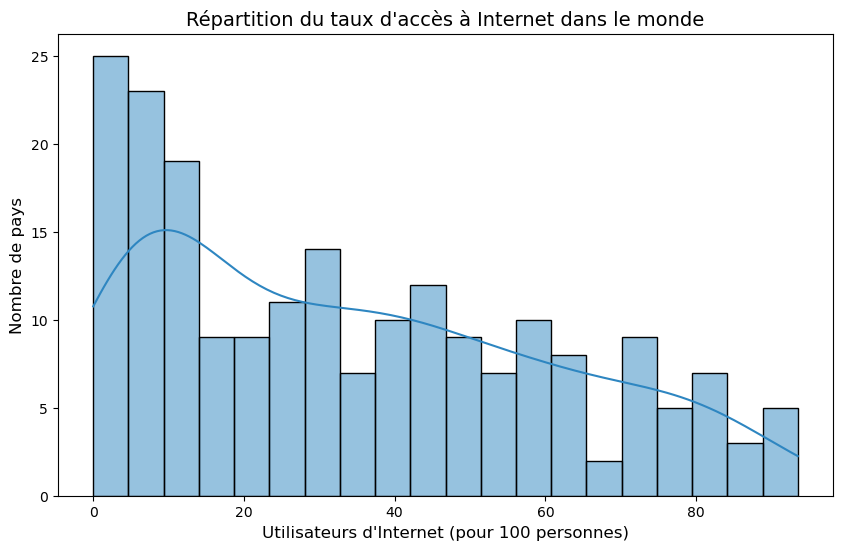

In [169]:
# Taux d'accès à internet
plt.figure(figsize=(10, 6))
sns.histplot(df_final['Internet users (per 100 people)'].dropna(), 
             bins=20, 
             kde=True, 
             color='#2E86C1'
             ) 
plt.title("Répartition du taux d'accès à Internet dans le monde", fontsize=14)
plt.xlabel("Utilisateurs d'Internet (pour 100 personnes)", fontsize=12)
plt.ylabel("Nombre de pays", fontsize=12)

plt.show()

On constate qu'il y a beaucoup de pays avec un taux d'accès à internet bas. Supprimer ces pays ?

Text(0.5, 1.0, "Taux brut de scolarisation dans l’enseignement en fonction de l'accès à internet")

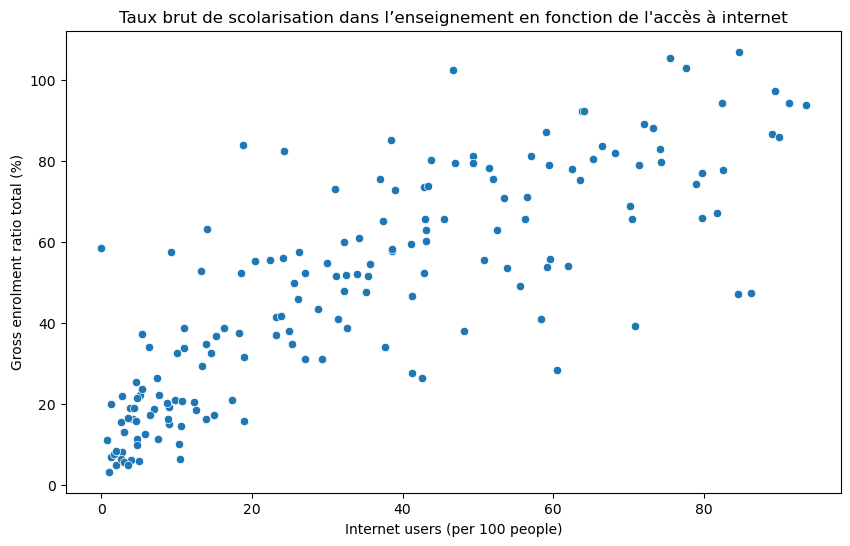

In [171]:
# T
plt.figure(figsize=(10, 6))
sns.scatterplot(data = df_final, 
            x=df_final['Internet users (per 100 people)'],
            y=df_final['Gross enrolment ratio total (%)'],     
               )
plt.title("Taux brut de scolarisation dans l’enseignement en fonction de l'accès à internet" )

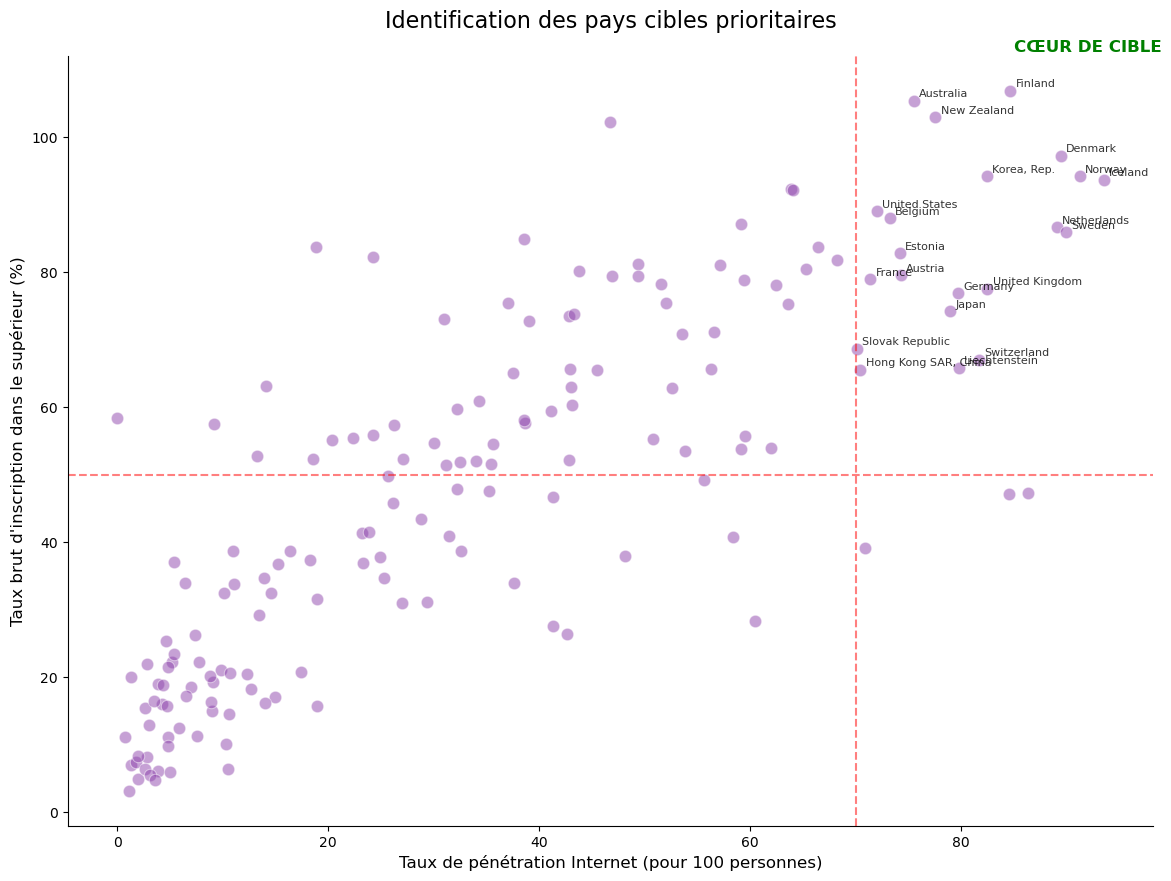

In [172]:

# Seuils stratégiques (choisis pour Academy)
seuil_internet = 70  # Seuil minimal d'accès internet pour Academy
seuil_etudes = 50   # Seuil minimal de taux d'inscription
col_internet = 'Internet users (per 100 people)'
col_etudes = 'Gross enrolment ratio total (%)'

# Préparation des données (filtrage des NaN et identification des cibles)
df_plot = df_final.dropna(subset=[col_internet, col_etudes]).copy()

# On garde uniquement les pays ciblés
pays_cibles = df_plot[(df_plot[col_internet] > seuil_internet) & 
                       (df_plot[col_etudes] > seuil_etudes)]

# Graphique
plt.figure(figsize=(14, 10)) 
sns.scatterplot(data=df_plot, 
                x=col_internet, 
                y=col_etudes, 
                alpha=0.5, 
                color='#8E44AD', 
                s=80)

# Ajout des lignes de seuil
plt.axvline(x=seuil_internet, color='red', linestyle='--', alpha=0.5)
plt.axhline(y=seuil_etudes, color='red', linestyle='--', alpha=0.5)

# 4. Ajout des noms des pays cibles (la partie clé)
for index, row in pays_cibles.iterrows():
    # 'index' correspond au nom du pays (l'index du DataFrame)
    plt.text(x = row[col_internet] + 0.5,  # Petit décalage horizontal pour la lisibilité
             y = row[col_etudes] + 0.5,    # Petit décalage vertical
             s = index,                  # Le texte à afficher (nom du pays)
             fontdict=dict(color='black', alpha=0.8, size=8)) # Style du texte

# Titres
plt.title("Identification des pays cibles prioritaires", fontsize=16, pad=20)
plt.xlabel("Taux de pénétration Internet (pour 100 personnes)", fontsize=12)
plt.ylabel("Taux brut d'inscription dans le supérieur (%)", fontsize=12)
plt.text(85, 110, "CŒUR DE CIBLE\n", color='green', fontsize=12, weight='bold')

sns.despine()
plt.show()

Notes :
"Gross" sigifie taux brut car les inscrits incluent des personnes de tout âge, et pas uniquement la population qui a l'âge officiel pour ces études (c'est pour cela que l'on peut dépasser les 100%)

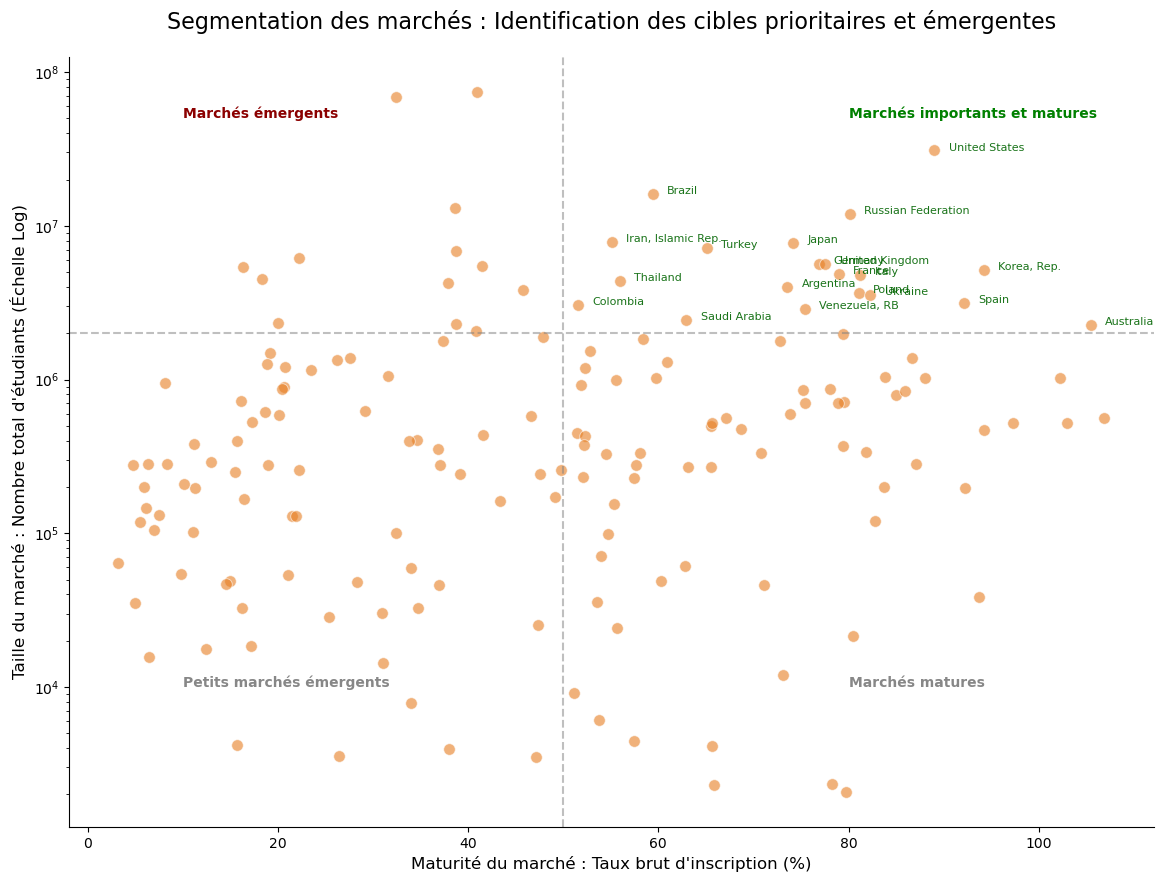

In [174]:

# Définition des colonnes et préparation des données
col_ratio = 'Gross enrolment ratio total (%)'
col_volume = 'Enrolment total secondary and tertiary (number)'
df_marche = df_final.dropna(subset=[col_ratio, col_volume]).copy()  # On supprime les pays auxquels il manque une des 2 données

# Définition des seuils 
seuil_ratio = 50
seuil_volume = 2000000 # 2 millions d'étudiants

# Création du graphique
plt.figure(figsize=(14, 10))

sns.scatterplot(data=df_marche, 
                x=col_ratio, 
                y=col_volume, 
                alpha=0.6, 
                color='#E67E22', 
                s=70)

plt.yscale('log')
plt.axvline(x=seuil_ratio, color='grey', linestyle='--', alpha=0.5)
plt.axhline(y=seuil_volume, color='grey', linestyle='--', alpha=0.5)

# Noms des pays cibles

pays_cibles = df_marche[(df_marche[col_ratio] > seuil_ratio) & 
                         (df_marche[col_volume] > seuil_volume)]

for pays, row in pays_cibles.iterrows():
    plt.text(x=row[col_ratio] + 1.5, 
             y=row[col_volume],       
             s=pays, 
             fontdict=dict(color='darkgreen', size=8, alpha=0.9))


# Titres

plt.title("Segmentation des marchés : Identification des cibles prioritaires et émergentes", fontsize=16, pad=20)
plt.xlabel("Maturité du marché : Taux brut d'inscription (%)", fontsize=12)
plt.ylabel("Taille du marché : Nombre total d'étudiants (Échelle Log)", fontsize=12)

# Annotations des quadrants
plt.text(10, 50000000, "Marchés émergents", color='darkred', weight='bold')
plt.text(80, 50000000, "Marchés importants et matures", color='green', weight='bold') 
plt.text(10, 10000, "Petits marchés émergents", color='dimgrey', weight='bold', alpha=0.8)
plt.text(80, 10000, "Marchés matures", color='dimgrey', weight='bold', alpha=0.8)

sns.despine()
plt.show()

In [175]:
from IPython.display import display
# Tableau 1 : Marchés importants et matures
marches_importants = df_marche[(df_marche[col_ratio] > seuil_ratio) & 
                            (df_marche[col_volume] > seuil_volume)].copy()
marches_importants = marches_importants.sort_values(by=col_volume, ascending=False)

print("TABLEAU 1 : Marchés importants et matures ")
print("Pays avec > 1 million d'étudiants et> 50% d'inscriptions")

display(marches_importants[[col_ratio, col_volume]].style.format({
    col_ratio: "{:.1f}%", 
    col_volume: "{:,.0f}"
}))

TABLEAU 1 : Marchés importants et matures 
Pays avec > 1 million d'étudiants et> 50% d'inscriptions


Indicator Name,Gross enrolment ratio total (%),Enrolment total secondary and tertiary (number)
Country Name,,
United States,89.0%,"30,905,037"
Brazil,59.4%,"16,067,684"
Russian Federation,80.1%,"11,937,559"
"Iran, Islamic Rep.",55.1%,"7,823,863"
Japan,74.2%,"7,684,479"
Turkey,65.1%,"7,171,413"
Germany,76.9%,"5,648,160"
United Kingdom,77.6%,"5,618,502"
"Korea, Rep.",94.2%,"5,162,328"


In [176]:
# Tableau 2 : Marchés émergents

marches_emergents = df_marche[(df_marche[col_ratio] <= seuil_ratio) & 
                              (df_marche[col_volume] > seuil_volume)].copy()
marches_emergents = marches_emergents.sort_values(by=col_volume, ascending=False)

print("TABLEAU 2 : MARCHES EMERGENTS")
print("Pays avec > 1 million d'étudiants et  <= 50% d'inscriptions")
display(marches_emergents[[col_ratio, col_volume]].style.format({
    col_ratio: "{:.1f}%", 
    col_volume: "{:,.0f}"
}))

TABLEAU 2 : MARCHES EMERGENTS
Pays avec > 1 million d'étudiants et  <= 50% d'inscriptions


Indicator Name,Gross enrolment ratio total (%),Enrolment total secondary and tertiary (number)
Country Name,,
China,41.0%,"74,508,073"
India,32.4%,"68,550,574"
Indonesia,38.7%,"13,146,412"
Mexico,38.7%,"6,880,387"
Bangladesh,22.2%,"6,187,377"
"Egypt, Arab Rep.",41.4%,"5,462,376"
Pakistan,16.3%,"5,360,539"
Nigeria,18.3%,"4,500,862"
Philippines,37.8%,"4,276,223"


In [177]:
# Tableau 3 : Marchés matures

marches_matures = df_marche[(df_marche[col_ratio] > seuil_ratio) & 
                            (df_marche[col_volume] <= seuil_volume)].copy()
marches_matures = marches_matures.sort_values(by=col_volume, ascending=False)

print("TABLEAU 3 : Marchés iplus petits mais matures ")
print("Pays avec < 1 million d'étudiants et> 50% d'inscriptions")

display(marches_matures[[col_ratio, col_volume]].style.format({
    col_ratio: "{:.1f}%", 
    col_volume: "{:,.0f}"
}))

TABLEAU 3 : Marchés iplus petits mais matures 
Pays avec < 1 million d'étudiants et> 50% d'inscriptions


Indicator Name,Gross enrolment ratio total (%),Enrolment total secondary and tertiary (number)
Country Name,,
Chile,79.5%,"1,966,183"
"Korea, Dem. People’s Rep.",58.3%,"1,831,404"
Romania,72.8%,"1,771,688"
Sri Lanka,52.8%,"1,542,543"
Netherlands,86.7%,"1,374,067"
Kazakhstan,60.9%,"1,304,404"
Ecuador,52.3%,"1,189,446"
Cuba,83.8%,"1,041,400"
Belgium,88.0%,"1,023,511"


In [178]:
# On récupère l'information du PIB par habitants pour les pays cibles

In [179]:
richesse_pays = EdStatsCountry[['Table Name', 'Income Group']].copy()
richesse_pays.head()

,Table Name,Income Group
0,Aruba,High income: nonOECD
1,Afghanistan,Low income
2,Angola,Upper middle income
3,Albania,Upper middle income
4,Andorra,High income: nonOECD


In [180]:
marches_importants = marches_importants.merge(
    richesse_pays[['Table Name', 'Income Group']],
    left_index=True,
    right_on='Table Name',
    how='left'
)


In [181]:
marches_importants = marches_importants.set_index('Table Name')
marches_importants

,GDP per capita (current US$),Internet users (per 100 people),Personal computers (per 100 people),"Population ages 15-25, total",Enrolment total secondary and tertiary (number),Population of the official age total (number),Gross enrolment ratio total (%),Income Group
Table Name,,,,,,,,
United States,49789,72,79,49035442,30905037,34717992,89,High income: OECD
Brazil,9543,41,16,37565261,16067684,27044022,59,Upper middle income
Russian Federation,10962,44,13,22348568,11937559,14898742,80,High income: nonOECD
"Iran, Islamic Rep.",5594,20,10,17930096,7823863,14192902,55,Upper middle income
Japan,40220,79,NaN,14300891,7684479,10355572,74,High income: OECD
Turkey,10400,37,6,15071923,7171413,11013158,65,Upper middle income
Germany,42632,80,62,10321377,5648160,7343272,77,High income: OECD
United Kingdom,43369,82,78,8738451,5618502,7243706,78,High income: OECD
"Korea, Rep.",22968,82,56,7370406,5162328,5479265,94,High income: OECD


In [184]:
marches_importants.shape

(20, 8)

In [186]:
# On remplace les NaN
mediane_high_income = marches_importants.loc[marches_importants['Income Group'] == 'High income: OECD', 'Personal computers (per 100 people)'].median()
marches_importants['Personal computers (per 100 people)'] = marches_importants['Personal computers (per 100 people)'].fillna(mediane_high_income)

In [188]:
marches_importants

,GDP per capita (current US$),Internet users (per 100 people),Personal computers (per 100 people),"Population ages 15-25, total",Enrolment total secondary and tertiary (number),Population of the official age total (number),Gross enrolment ratio total (%),Income Group
Table Name,,,,,,,,
United States,49789,72,79,49035442,30905037,34717992,89,High income: OECD
Brazil,9543,41,16,37565261,16067684,27044022,59,Upper middle income
Russian Federation,10962,44,13,22348568,11937559,14898742,80,High income: nonOECD
"Iran, Islamic Rep.",5594,20,10,17930096,7823863,14192902,55,Upper middle income
Japan,40220,79,58,14300891,7684479,10355572,74,High income: OECD
Turkey,10400,37,6,15071923,7171413,11013158,65,Upper middle income
Germany,42632,80,62,10321377,5648160,7343272,77,High income: OECD
United Kingdom,43369,82,78,8738451,5618502,7243706,78,High income: OECD
"Korea, Rep.",22968,82,56,7370406,5162328,5479265,94,High income: OECD


In [192]:
marches_importants.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20 entries, United States to Australia
Data columns (total 8 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   GDP per capita (current US$)                     20 non-null     float64
 1   Internet users (per 100 people)                  20 non-null     float64
 2   Personal computers (per 100 people)              20 non-null     float64
 3   Population ages 15-25, total                     20 non-null     float64
 4   Enrolment total secondary and tertiary (number)  20 non-null     float64
 5   Population of the official age total (number)    20 non-null     float64
 6   Gross enrolment ratio total (%)                  20 non-null     float64
 7   Income Group                                     20 non-null     object 
dtypes: float64(7), object(1)
memory usage: 1.9+ KB


In [190]:
marches_importants.describe()

,GDP per capita (current US$),Internet users (per 100 people),Personal computers (per 100 people),"Population ages 15-25, total",Enrolment total secondary and tertiary (number),Population of the official age total (number),Gross enrolment ratio total (%)
count,20,20,20,20,20,20,20
mean,23032,53,33,12892861,6850026,9278053,76
std,16896,21,26,11560919,6590349,8228308,14
min,3026,20,4,3185259,2252326,2136178,52
25%,9881,37,9,6319949,3431943,4452304,65
50%,16107,47,25,8585216,4822103,6034070,77
75%,40335,73,58,14493649,7299680,10519968,81
max,51990,82,79,49035442,30905037,34717992,105


In [196]:
marches_importants.index

Index(['United States', 'Brazil', 'Russian Federation', 'Iran, Islamic Rep.',
       'Japan', 'Turkey', 'Germany', 'United Kingdom', 'Korea, Rep.', 'France',
       'Italy', 'Thailand', 'Argentina', 'Poland', 'Ukraine', 'Spain',
       'Colombia', 'Venezuela, RB', 'Saudi Arabia', 'Australia'],
      dtype='object', name='Table Name')

In [198]:
# On supprime les pays qui posent problème d'un point de vue géopolitique
pays_a_supprimer = ['Russian Federation', 'Iran, Islamic Rep.', 'Venezuela, RB', 'Ukraine']
marches_importants = marches_importants[~marches_importants.index.isin(pays_a_supprimer)].copy()
print(f"Nombre de pays finaux ciblés : {len(marches_importants)}")
print("Liste finale :", list(marches_importants.index))

Nombre de pays finaux ciblés : 16
Liste finale : ['United States', 'Brazil', 'Japan', 'Turkey', 'Germany', 'United Kingdom', 'Korea, Rep.', 'France', 'Italy', 'Thailand', 'Argentina', 'Poland', 'Spain', 'Colombia', 'Saudi Arabia', 'Australia']


In [204]:
marches_importants

,GDP per capita (current US$),Internet users (per 100 people),Personal computers (per 100 people),"Population ages 15-25, total",Enrolment total secondary and tertiary (number),Population of the official age total (number),Gross enrolment ratio total (%),Income Group
Table Name,,,,,,,,
United States,49789,72,79,49035442,30905037,34717992,89,High income: OECD
Brazil,9543,41,16,37565261,16067684,27044022,59,Upper middle income
Japan,40220,79,58,14300891,7684479,10355572,74,High income: OECD
Turkey,10400,37,6,15071923,7171413,11013158,65,Upper middle income
Germany,42632,80,62,10321377,5648160,7343272,77,High income: OECD
United Kingdom,43369,82,78,8738451,5618502,7243706,78,High income: OECD
"Korea, Rep.",22968,82,56,7370406,5162328,5479265,94,High income: OECD
France,40678,71,61,8431981,4884298,6182528,79,High income: OECD
Italy,35511,49,37,6445101,4759907,5860603,81,High income: OECD


In [238]:
# On renomme les colonnes en français
df_final = marches_importants.rename(columns = 
                {'GDP per capita (current US$)': 'PIB par habitant (USD)',
                'Internet users (per 100 people)': 'Utilisateurs Internet (pour 100 hab.)',
                'Personal computers (per 100 people)' : 'Ordinateurs persos (pour 100 hab)',
                'Population ages 15-25, total' : 'Total 15-25 ans',
                'Enrolment total secondary and tertiary (number)': 'Total inscrits (Secondaire + Supérieur)',
                'Population of the official age total (number)' : 'Population totale en âge officiel études (nombre)',
                'Gross enrolment ratio total (%)': 'Taux brut inscription total (%)',
                'Income Group': 'Niveau de revenus' }   )                 

In [240]:
df_final

,PIB par habitant (USD),Utilisateurs Internet (pour 100 hab.),Ordinateurs persos (pour 100 hab),Total 15-25 ans,Total inscrits (Secondaire + Supérieur),Population totale en âge officiel études (nombre),Taux brut inscription total (%),Niveau de revenus
Table Name,,,,,,,,
United States,49789,72,79,49035442,30905037,34717992,89,High income: OECD
Brazil,9543,41,16,37565261,16067684,27044022,59,Upper middle income
Japan,40220,79,58,14300891,7684479,10355572,74,High income: OECD
Turkey,10400,37,6,15071923,7171413,11013158,65,Upper middle income
Germany,42632,80,62,10321377,5648160,7343272,77,High income: OECD
United Kingdom,43369,82,78,8738451,5618502,7243706,78,High income: OECD
"Korea, Rep.",22968,82,56,7370406,5162328,5479265,94,High income: OECD
France,40678,71,61,8431981,4884298,6182528,79,High income: OECD
Italy,35511,49,37,6445101,4759907,5860603,81,High income: OECD


# Exercice Partie 3 - Analysez des données de systèmes éducatifs

## Etape 1 - Identifiez les indicateurs redondants d'un point de vue statistique

### Matrice de corrélation de l'ensemble des indicateurs

In [242]:
#Méthode Pearson
df_numerique = df_final.select_dtypes(include=['float64', 'int64'])
methode_pearson = df_numerique.corr(method='pearson')
methode_pearson

,PIB par habitant (USD),Utilisateurs Internet (pour 100 hab.),Ordinateurs persos (pour 100 hab),Total 15-25 ans,Total inscrits (Secondaire + Supérieur),Population totale en âge officiel études (nombre),Taux brut inscription total (%)
PIB par habitant (USD),1,1,1,0,0,0,1
Utilisateurs Internet (pour 100 hab.),1,1,1,-0,0,-0,1
Ordinateurs persos (pour 100 hab),1,1,1,0,0,0,1
Total 15-25 ans,0,-0,0,1,1,1,-0
Total inscrits (Secondaire + Supérieur),0,0,0,1,1,1,0
Population totale en âge officiel études (nombre),0,-0,0,1,1,1,-0
Taux brut inscription total (%),1,1,1,-0,0,-0,1


In [244]:
# Méthode Spearman
methode_spearman = df_numerique.corr(method='spearman')
methode_spearman

,PIB par habitant (USD),Utilisateurs Internet (pour 100 hab.),Ordinateurs persos (pour 100 hab),Total 15-25 ans,Total inscrits (Secondaire + Supérieur),Population totale en âge officiel études (nombre),Taux brut inscription total (%)
PIB par habitant (USD),1,1,1,-0,0,-0,1
Utilisateurs Internet (pour 100 hab.),1,1,1,-0,0,-0,1
Ordinateurs persos (pour 100 hab),1,1,1,0,0,0,1
Total 15-25 ans,-0,-0,0,1,1,1,-0
Total inscrits (Secondaire + Supérieur),0,0,0,1,1,1,-0
Population totale en âge officiel études (nombre),-0,-0,0,1,1,1,-0
Taux brut inscription total (%),1,1,1,-0,-0,-0,1


In [246]:
# Visualisation avec une heatmap

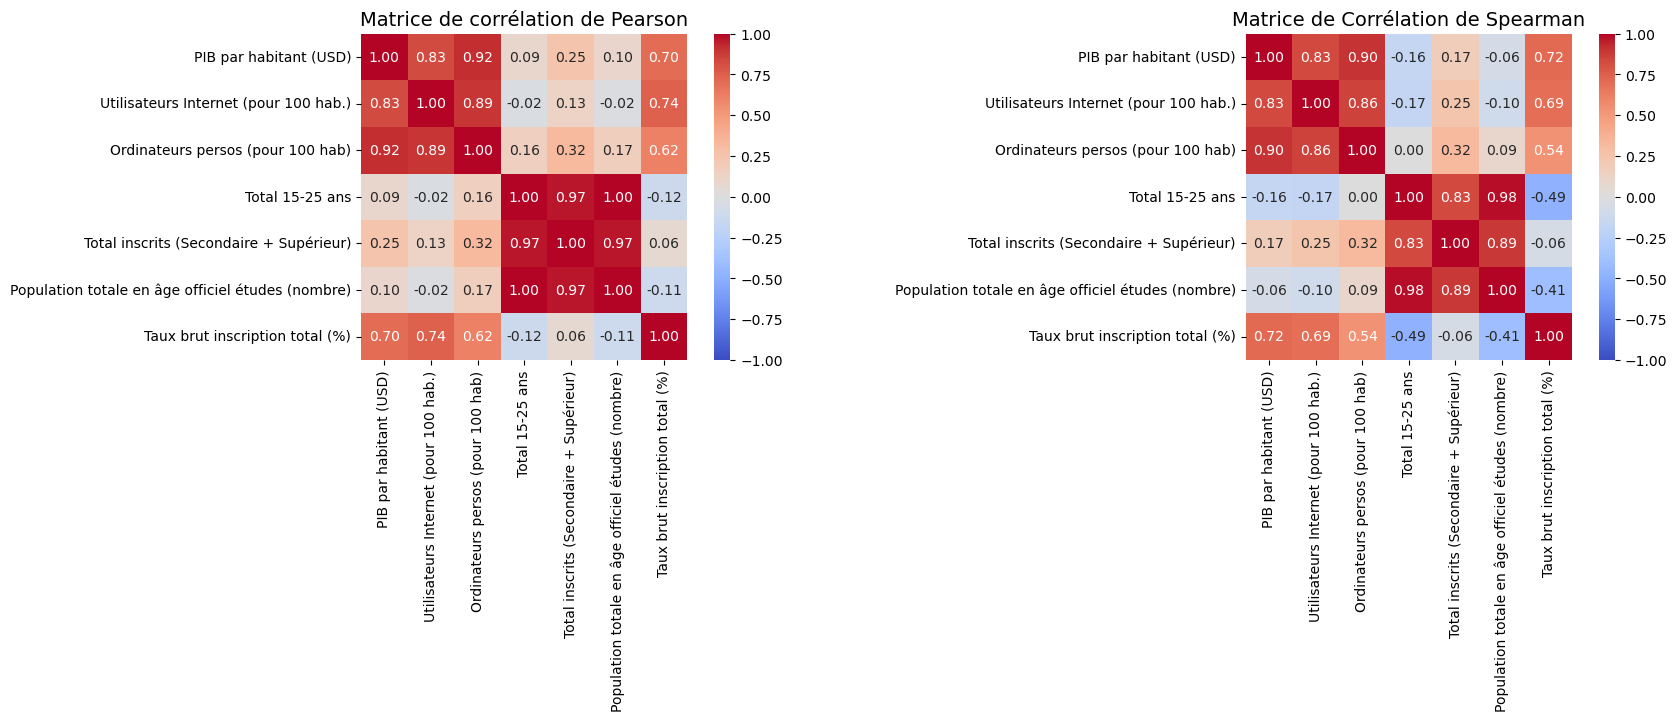

In [248]:
# Heatmap Pearson
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(methode_pearson, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, center=0, ax=axes[0], square=True)
axes[0].set_title("Matrice de corrélation de Pearson", fontsize=14)

# Heatmap Spearman
sns.heatmap(methode_spearman, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, center=0, ax=axes[1], square=True)
axes[1].set_title("Matrice de Corrélation de Spearman", fontsize=14)

plt.tight_layout()
plt.show()

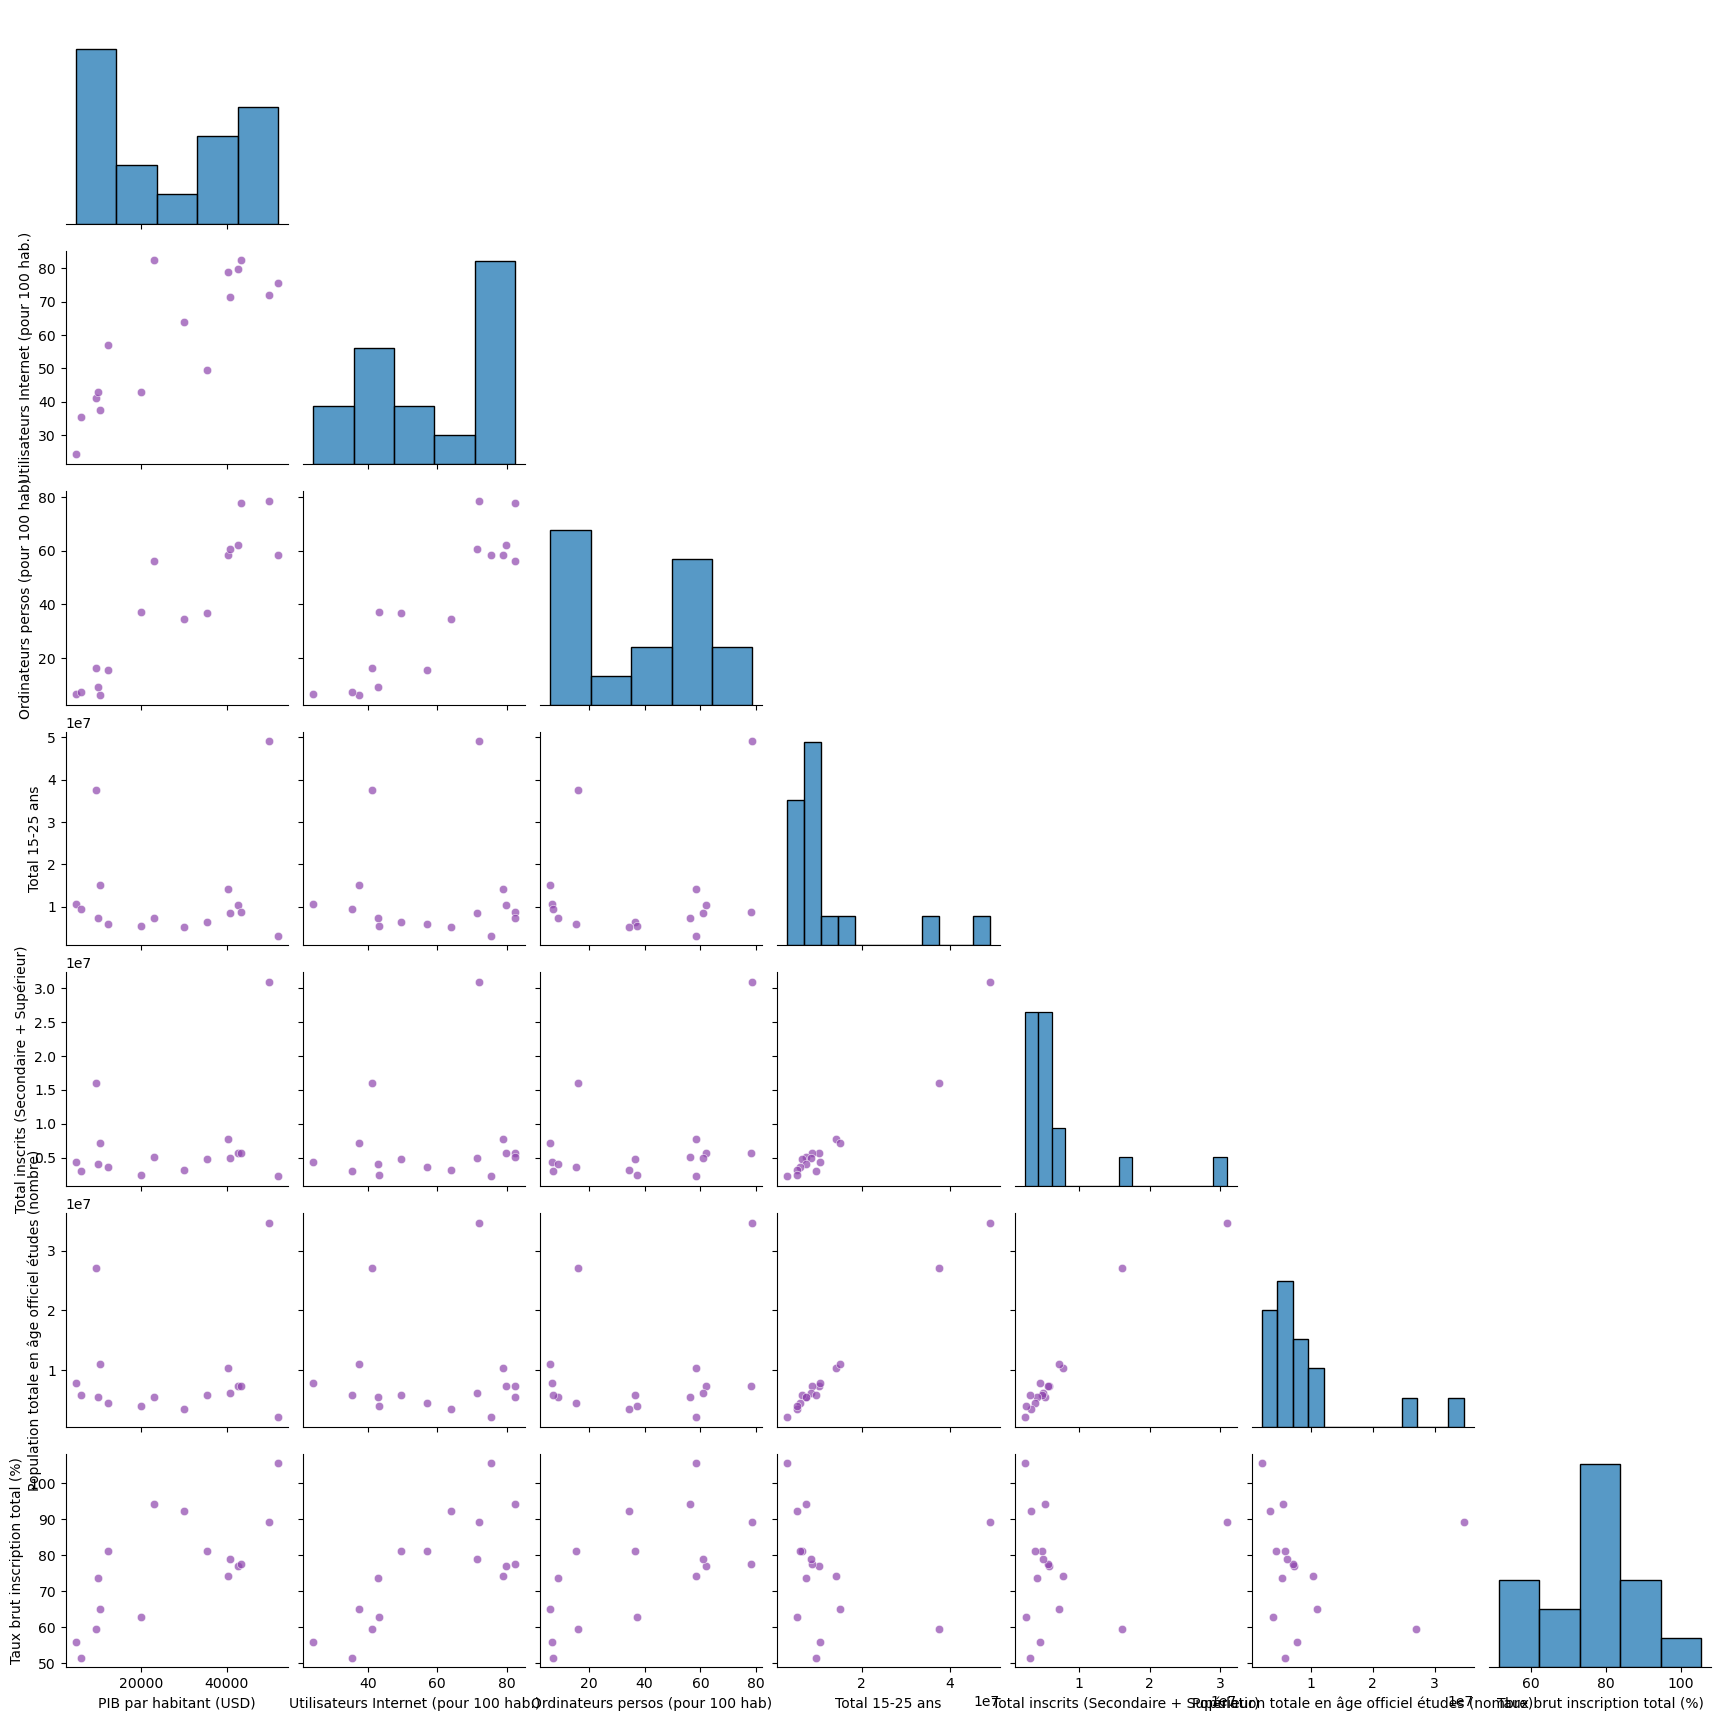

In [250]:
# 4. Pairplot
sns.pairplot(df_numerique, corner=True, plot_kws={'alpha': 0.7, 'color': '#8E44AD'})
plt.show()

In [260]:
# Suppression des indicateurs redondants
# Liste des colonnes redondantes à supprimer (suite à notre analyse métier)
colonnes_a_supprimer = [
    'Total 15-25 ans',
    'Total inscrits (Secondaire + Supérieur)',
    'Ordinateurs persos (pour 100 hab)'
]

# On supprime ces colonnes
df_final_academy = df_final.drop(columns=colonnes_a_supprimer)

print(f"Dimensions du dataFrame final : {df_final_academy.shape}")
print("Colonnes conservées pour l'analyse :")
print(df_final_academy.columns.tolist())

# Aperçu final
df_final_academy


Dimensions du dataFrame final : (16, 5)
Colonnes conservées pour l'analyse :
['PIB par habitant (USD)', 'Utilisateurs Internet (pour 100 hab.)', 'Population totale en âge officiel études (nombre)', 'Taux brut inscription total (%)', 'Niveau de revenus']


,PIB par habitant (USD),Utilisateurs Internet (pour 100 hab.),Population totale en âge officiel études (nombre),Taux brut inscription total (%),Niveau de revenus
Table Name,,,,,
United States,49789,72,34717992,89,High income: OECD
Brazil,9543,41,27044022,59,Upper middle income
Japan,40220,79,10355572,74,High income: OECD
Turkey,10400,37,11013158,65,Upper middle income
Germany,42632,80,7343272,77,High income: OECD
United Kingdom,43369,82,7243706,78,High income: OECD
"Korea, Rep.",22968,82,5479265,94,High income: OECD
France,40678,71,6182528,79,High income: OECD
Italy,35511,49,5860603,81,High income: OECD


## Etape 2 - Analysez vos indicateurs restants et formulez une liste de pays pertinents pour l'implantation d'Academy

In [274]:
# Calcul des statistiques descriptives d'un indicateur
df_final_academy['Utilisateurs Internet (pour 100 hab.)'].describe()


count   16
mean    59
std     20
min     24
25%     42
50%     61
75%     76
max     82
Name: Utilisateurs Internet (pour 100 hab.), dtype: float64

Ecart-type de 20 : il y a de fortes disparités technologiques au sein de ce groupe de 16 pays.
Le 1er quart des pays possède 42 utilisateurs pour 100 hab ou moins.  
La moitié des pays en a moins de 61 et l'autre moitié en a + de 61. 
75% des pays ont un taux inférieur de 76%
Les 4 derniers pays se situe entre 76 et 82 (le max)

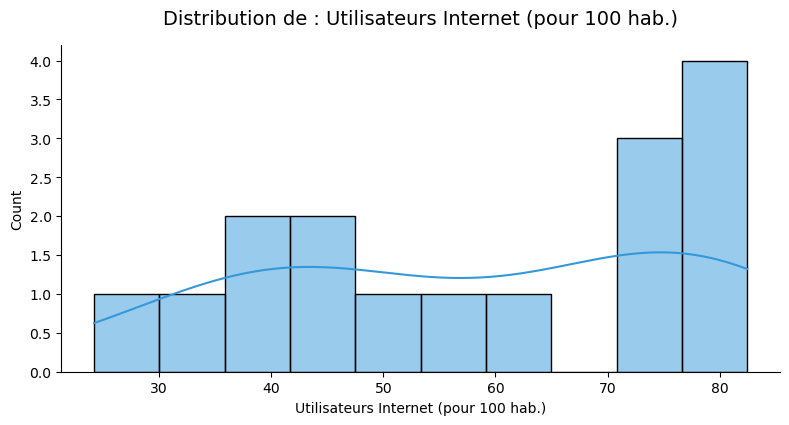

In [280]:
# Affichage de sa distribution
sns.displot(data=df_final_academy, x='Utilisateurs Internet (pour 100 hab.)', kde=True, bins=10, color='#3498DB', height=4, aspect=2)
plt.title('Distribution de : Utilisateurs Internet (pour 100 hab.)', fontsize=14, pad=15)
plt.show()

In [ ]:
# Fonction pour les autres indicateurs


count      16
mean    26890
std     16708
min      4835
25%     10299
50%     26546
75%     41166
max     51990
Name: PIB par habitant (USD), dtype: float64

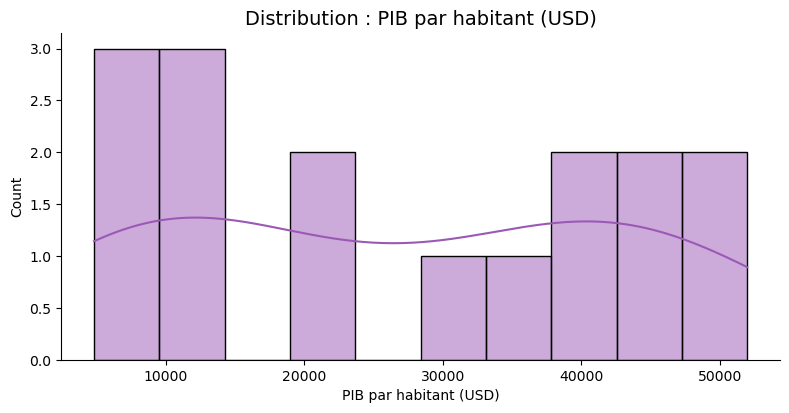

count   16
mean    59
std     20
min     24
25%     42
50%     61
75%     76
max     82
Name: Utilisateurs Internet (pour 100 hab.), dtype: float64

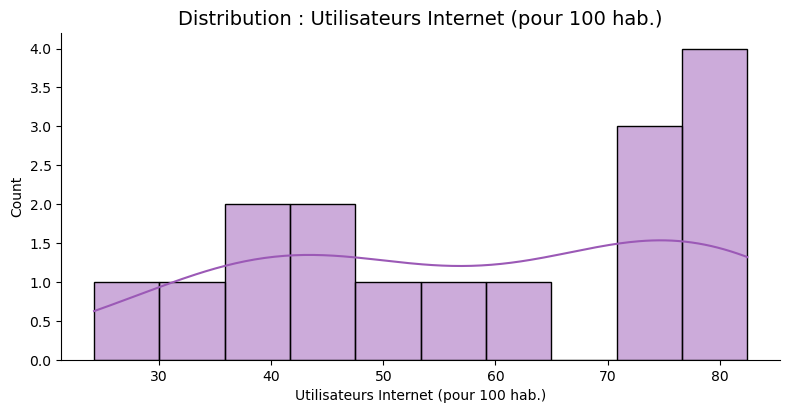

count         16
mean     9271417
std      8854966
min      2136178
25%      5219605
50%      6034070
75%      8460937
max     34717992
Name: Population totale en âge officiel études (nombre), dtype: float64

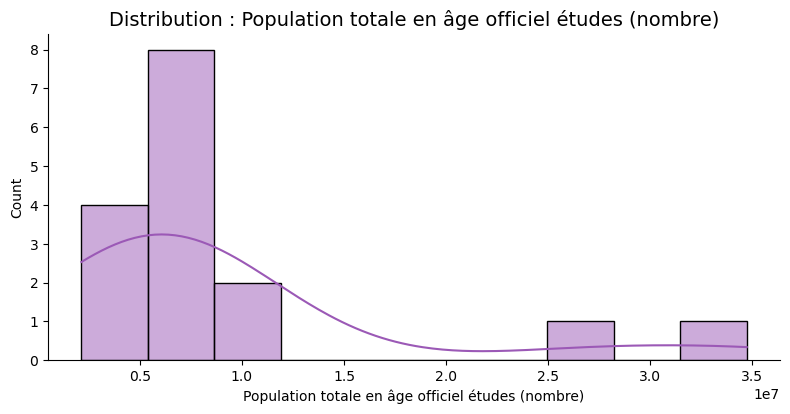

count    16
mean     76
std      15
min      52
25%      65
50%      77
75%      83
max     105
Name: Taux brut inscription total (%), dtype: float64

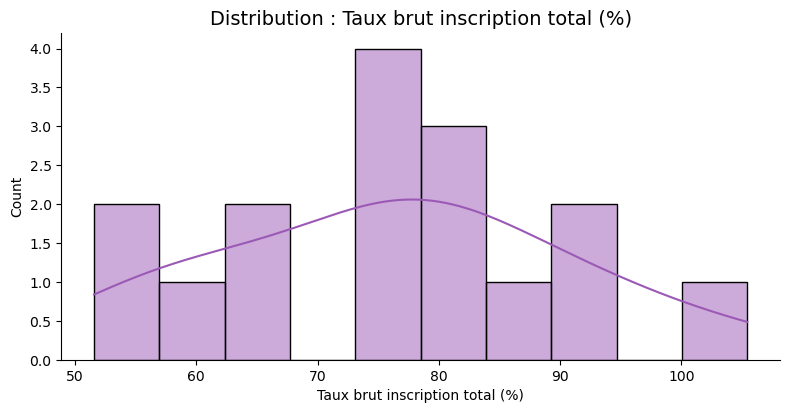

In [286]:
# Définition de la fonction
def analyser_distribution(df, colonne):
    # Statistique
    display(df[colonne].describe())
    
    # Graphique
    sns.displot(data=df, x=colonne, kde=True, bins=10, color='#9B59B6', height=4, aspect=2)
    plt.title(f"Distribution : {colonne}", fontsize=14)
    plt.show()

# Liste des colonnes numériques
colonnes_numeriques = [
    'PIB par habitant (USD)', 
    'Utilisateurs Internet (pour 100 hab.)', 
    'Population totale en âge officiel études (nombre)', 
    'Taux brut inscription total (%)'
]

# Boucle for pour tout analyser automatiquement
for col in colonnes_numeriques:
    analyser_distribution(df_final_academy, col)

In [333]:
list_pays_top_5=[]
for col in colonnes_numeriques : 
    top_5 = df_final_academy[col].sort_values(ascending=False).head().index.tolist()
    print(f"Top 5 pour {col} : {top_5}")
    list_pays_top_5.extend(top_5)
print(f"Liste complète des pays des top 5 : {list_pays_top_5}")

Top 5 pour PIB par habitant (USD) : ['Australia', 'United States', 'United Kingdom', 'Germany', 'France']
Top 5 pour Utilisateurs Internet (pour 100 hab.) : ['United Kingdom', 'Korea, Rep.', 'Germany', 'Japan', 'Australia']
Top 5 pour Population totale en âge officiel études (nombre) : ['United States', 'Brazil', 'Turkey', 'Japan', 'Thailand']
Top 5 pour Taux brut inscription total (%) : ['Australia', 'Korea, Rep.', 'Spain', 'United States', 'Italy']
Liste complète des pays des top 5 : ['Australia', 'United States', 'United Kingdom', 'Germany', 'France', 'United Kingdom', 'Korea, Rep.', 'Germany', 'Japan', 'Australia', 'United States', 'Brazil', 'Turkey', 'Japan', 'Thailand', 'Australia', 'Korea, Rep.', 'Spain', 'United States', 'Italy']


In [343]:
nb_pays_top_5 = Counter(list_pays_top_5)
nb_pays_top_5

Counter({'Australia': 3,
         'United States': 3,
         'United Kingdom': 2,
         'Germany': 2,
         'Korea, Rep.': 2,
         'Japan': 2,
         'France': 1,
         'Brazil': 1,
         'Turkey': 1,
         'Thailand': 1,
         'Spain': 1,
         'Italy': 1})

TOP 6 selon la méthode des pays les + récurrents dans les différents top 5 :
Australie  
USA  
Royaume-Uni  
Allemagne  
Corée du Sud  
Japon

In [349]:
# Copie du DataFrame pour ne pas altérer les données d'origine
df_scoring = df_final_academy.copy()

# Normalisation Min-Max (mise sur une échelle de 0 à 1)
for col in colonnes_numeriques:
    mini = df_scoring[col].min()
    maxi = df_scoring[col].max()
    df_scoring[f'{col}_norm'] = (df_scoring[col] - mini) / (maxi - mini)

# 3. Définition des poids stratégiques (Total = 100 points)
# - Population (40 points) : Academy a besoin de volume avant tout.
# - Internet (30 points) : L'infrastructure est vitale pour une EdTech.
# - Inscription (20 points) : Indique l'appétence pour les études.
# - PIB (10 points) : Moins critique, car le prix des abonnements peut être adapté.

# Calcul du Score
df_scoring['Score_Academy (/100)'] = (
    df_scoring['Population totale en âge officiel études (nombre)_norm'] * 40 +
    df_scoring['Utilisateurs Internet (pour 100 hab.)_norm'] * 30 +
    df_scoring['Taux brut inscription total (%)_norm'] * 20 +
    df_scoring['PIB par habitant (USD)_norm'] * 10
)

# Extraction du Top 5 des pays à recommander à Mark
top_pays = df_scoring.sort_values(by='Score_Academy (/100)', ascending=False)


display(top_pays[['Score_Academy (/100)', 'Niveau de revenus']].head(5).style.format({
    'Score_Academy (/100)': "{:.1f} pts"
}))

,Score_Academy (/100),Niveau de revenus
Table Name,,
United States,88.0 pts,High income: OECD
Australia,56.4 pts,High income: OECD
Japan,54.2 pts,High income: OECD
United Kingdom,54.1 pts,High income: OECD
"Korea, Rep.",53.8 pts,High income: OECD


TOP 5 selon la méthode des moyennes pondérées :
  
USA  
Australie  
Japon  
Royaume-Uni   
Corée du Sud  
